## ALMUZAHIM NASEEF MUHAMAD S24B38/006 B30296

# Computer Vision and Deep Learning - CNN Practical
## Google Colab Edition
### From Pixels and Filters to Learned Features, Training and Transfer Learning

This notebook is a **self-contained learning resource, executable practical, and guided assignment scaffold**. It continues from image arrays and handcrafted image operations into **Convolutional Neural Networks (CNNs)**.

Work through it in order. The repeated learning cycle is:

**READ → PREDICT → RUN → INSPECT → EXPLAIN → MODIFY → BUILD**

### Labels used in this notebook
- **DEMO** - working code is provided. Run it and understand every output.
- **PREDICT** - decide what you expect *before* running the next cell.
- **TRY IT** - make a small change and observe the effect.
- **CHECKPOINT** - explain what the evidence means in your own words.
- **TODO** - guided student work. Scaffolding is provided, but you must complete the reasoning and implementation.

> **Central question:** How does a CNN transform pixels into useful visual representations, how does training change those representations, and when should we train from scratch versus use transfer learning?

> **Important:** Do not treat neural-network code as magic syntax. Throughout the notebook, inspect **tensor shapes, activations, loss, gradients, learned filters, errors, and model attention evidence**.

## 0. Colab runtime setup

For the natural-image training sections, use a GPU if one is available:

**Runtime → Change runtime type → T4 GPU**

The notebook still has CPU fallbacks, but the larger training experiments will be slower.

The notebook **measures actual runtime and accuracy**. Exact numbers vary across Colab sessions, random initialization, package versions, and available hardware.

In [ ]:
import subprocess
# COLAB SETUP - run this cell first.
import os
import io
import gc
import math
import time
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib import cbook

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IN_COLAB = 'COLAB_RELEASE_TAG' in os.environ or 'google.colab' in str(get_ipython()) if 'get_ipython' in globals() else False
DATA_ROOT = Path('/content/cv_cnn_data') if Path('/content').exists() else Path('./cv_cnn_data')
DATA_ROOT.mkdir(parents=True, exist_ok=True)

print('PyTorch version:', torch.__version__)
print('Device:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU not available. Heavy training sections will be slower.')
print('Data directory:', DATA_ROOT.resolve())

PyTorch version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Data directory: /content/cv_cnn_data


## 1. Learning outcomes

By the end of this notebook, you should be able to:

1. explain convolution as a local weighted operation;
2. distinguish a handcrafted filter from a learned CNN filter;
3. explain channels, kernels, feature maps, stride, padding, ReLU, and pooling;
4. trace tensor dimensions through a CNN;
5. build a small CNN in PyTorch;
6. unpack one complete training step: **forward → loss → backward → update**;
7. prove that convolution filters change during learning;
8. train and evaluate a CNN on MNIST and on natural photographs;
9. visualize learned filters and intermediate activation maps;
10. identify overfitting, high-confidence errors, and possible shortcut learning;
11. use and interpret Grad-CAM visualizations;
12. explain why transfer learning can be unnecessary on a simple task but powerful on natural images;
13. compare accuracy, training cost, parameter count, model size, and inference time;
14. make an evidence-based model recommendation for a deployment scenario.

---
# PART A - FROM HANDCRAFTED FILTERS TO CNN OPERATIONS

## 2. Bridge from image processing: we chose the filter

In traditional image processing, we can choose a kernel ourselves and apply it across an image.

**Handcrafted approach**

`image + human-chosen kernel → response map`

A CNN uses the same basic idea of local weighted operations, but the important difference is that **training learns useful kernel values from data**.

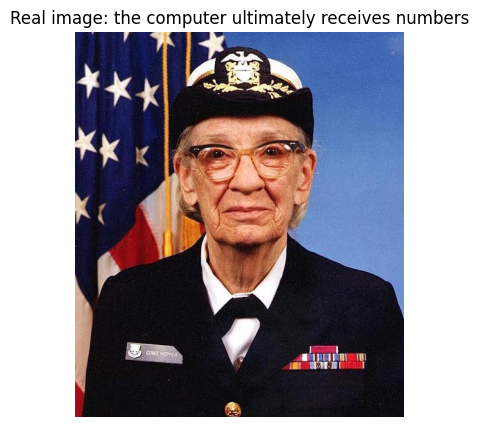

RGB size: (512, 600)
Grayscale numerical array: (256, 256) float32 range [0.004, 1.000]


In [ ]:
# DEMO - load a real photograph bundled with Matplotlib, so this section is self-contained.
sample_path = cbook.get_sample_data('grace_hopper.jpg')
sample_rgb = Image.open(sample_path).convert('RGB')
sample_gray = sample_rgb.convert('L').resize((256, 256))

gray_np = np.asarray(sample_gray, dtype=np.float32) / 255.0

plt.figure(figsize=(6, 5))
plt.imshow(sample_rgb)
plt.title('Real image: the computer ultimately receives numbers')
plt.axis('off')
plt.show()

print('RGB size:', sample_rgb.size)
print('Grayscale numerical array:', gray_np.shape, gray_np.dtype, f'range [{gray_np.min():.3f}, {gray_np.max():.3f}]')

### PREDICT
A vertical-edge kernel gives a strong response where intensity changes sharply from left to right.

Before running the next cell, predict which parts of the photograph will produce strong responses.

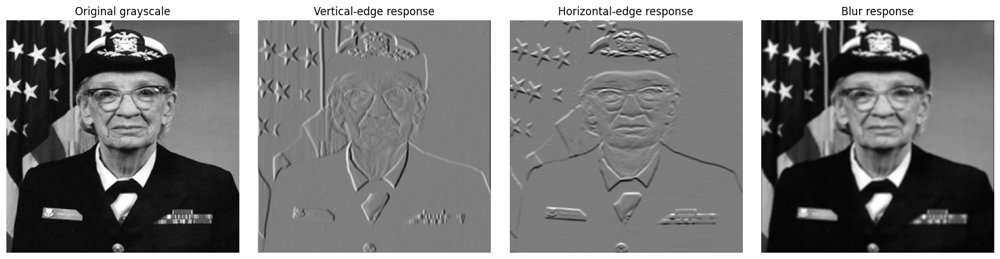

In [ ]:
# DEMO - fixed handcrafted kernels.
vertical_edge = torch.tensor([
    [-1., 0., 1.],
    [-1., 0., 1.],
    [-1., 0., 1.]
])
horizontal_edge = torch.tensor([
    [-1., -1., -1.],
    [ 0.,  0.,  0.],
    [ 1.,  1.,  1.]
])
blur_kernel = torch.ones((3, 3), dtype=torch.float32) / 9.0

image_tensor = torch.from_numpy(gray_np).unsqueeze(0).unsqueeze(0)

def apply_fixed_kernel(image_4d, kernel_2d, padding=1):
    k = kernel_2d.unsqueeze(0).unsqueeze(0)
    return F.conv2d(image_4d, k, padding=padding).squeeze().numpy()

responses = {
    'Original grayscale': gray_np,
    'Vertical-edge response': apply_fixed_kernel(image_tensor, vertical_edge),
    'Horizontal-edge response': apply_fixed_kernel(image_tensor, horizontal_edge),
    'Blur response': apply_fixed_kernel(image_tensor, blur_kernel),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, arr) in zip(axes, responses.items()):
    ax.imshow(arr, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

### CHECKPOINT
1. Did the vertical and horizontal kernels respond to the same structures?

No

2. Which values were manually selected by us?

The kernels we wanted like blur, vertical and horizontal

3. What would have to change if we wanted the computer to **learn** useful filters instead?

By replacing the kernels with trainable parameters with a neural network architecture


## 3. One convolution calculation by hand

A CNN performs many local calculations. We will first compute **one output position** before asking PyTorch to do the whole operation.

In [ ]:
# DEMO - a tiny 5×5 image and a 3×3 filter.
tiny_image = torch.tensor([
    [1., 2., 0., 1., 0.],
    [0., 1., 3., 1., 1.],
    [2., 1., 0., 2., 0.],
    [1., 0., 2., 3., 1.],
    [0., 1., 1., 0., 2.],
])

tiny_kernel = torch.tensor([
    [ 1., 0., -1.],
    [ 1., 0., -1.],
    [ 1., 0., -1.],
])

print('Image:\n', tiny_image)
print('\nKernel:\n', tiny_kernel)

Image:
 tensor([[1., 2., 0., 1., 0.],
        [0., 1., 3., 1., 1.],
        [2., 1., 0., 2., 0.],
        [1., 0., 2., 3., 1.],
        [0., 1., 1., 0., 2.]])

Kernel:
 tensor([[ 1.,  0., -1.],
        [ 1.,  0., -1.],
        [ 1.,  0., -1.]])


### PREDICT
Use the **top-left 3×3 patch**. Multiply corresponding values and add them.

Write your expected first output value before running the next cell.

In [ ]:
patch = tiny_image[:3, :3]
manual_value = (patch * tiny_kernel).sum()

print('Top-left patch:\n', patch)
print('\nElement-wise product:\n', patch * tiny_kernel)
print('\nFirst convolution output value =', manual_value.item())

full_output = F.conv2d(
    tiny_image.unsqueeze(0).unsqueeze(0),
    tiny_kernel.unsqueeze(0).unsqueeze(0)
).squeeze()

print('\nFull valid convolution output:\n', full_output)
print('PyTorch top-left result =', full_output[0, 0].item())

Top-left patch:
 tensor([[1., 2., 0.],
        [0., 1., 3.],
        [2., 1., 0.]])

Element-wise product:
 tensor([[ 1.,  0., -0.],
        [ 0.,  0., -3.],
        [ 2.,  0., -0.]])

First convolution output value = 0.0

Full valid convolution output:
 tensor([[ 0.,  0.,  2.],
        [-2., -4.,  3.],
        [ 0., -3.,  0.]])
PyTorch top-left result = 0.0


### CHECKPOINT
The single number you calculated becomes **one cell in the output feature map**. The filter then moves to another local patch and repeats the operation.

Explain why the full 5×5 image with a 3×3 kernel and no padding produced a 3×3 output.

The kernel can only take 3*3 since thats the only space it has.

## 4. RGB images, channels, and multiple learned filters

For an RGB image, one convolution filter must account for **all three input channels**.

If a layer is:

```python
nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3)
```

then the weight tensor has shape:

`[8, 3, 3, 3]`

That means **8 filters × 3 input channels × 3 × 3**. Each filter produces one output feature map.

In [ ]:
# DEMO - inspect an actual Conv2d layer.
random_conv = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3, padding=1)
print('Weight tensor shape:', tuple(random_conv.weight.shape))
print('Bias tensor shape:', tuple(random_conv.bias.shape))

photo_tensor = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])(sample_rgb).unsqueeze(0)

with torch.no_grad():
    random_maps = random_conv(photo_tensor)

print('Input shape :', tuple(photo_tensor.shape))
print('Output shape:', tuple(random_maps.shape))

Weight tensor shape: (8, 3, 3, 3)
Bias tensor shape: (8,)
Input shape : (1, 3, 128, 128)
Output shape: (1, 8, 128, 128)


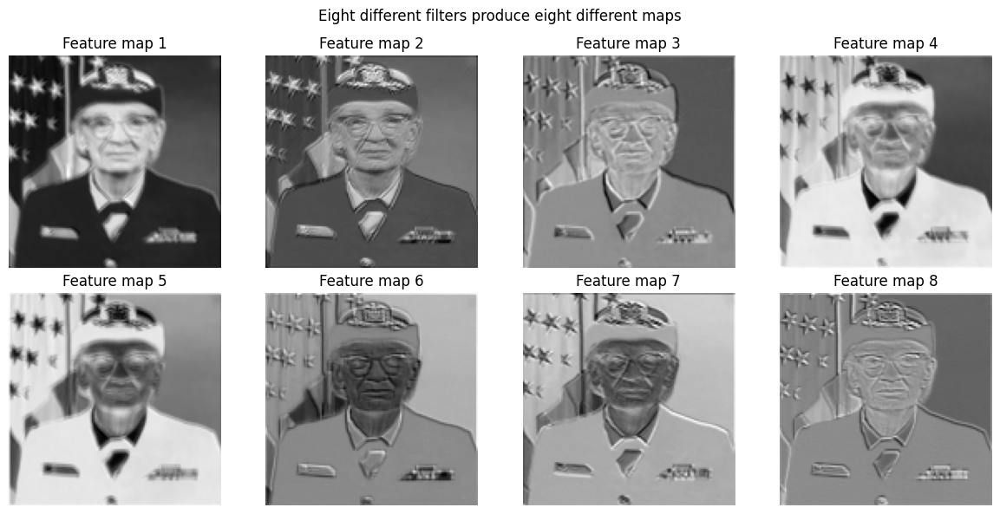

In [ ]:
# DEMO - visualize several feature maps from the random filters.
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(random_maps[0, i].numpy(), cmap='gray')
    ax.set_title(f'Feature map {i+1}')
    ax.axis('off')
plt.suptitle('Eight different filters produce eight different maps')
plt.tight_layout()
plt.show()

### CHECKPOINT
Why do the eight maps differ even though they all received the **same image**?

The images look different because each filter highlights a different aspect of the image.


## 5. Stride and padding change spatial dimensions

- **Stride** controls how far the filter moves between positions.
- **Padding** adds values around the boundary, often to preserve spatial size.

Predict each output shape before running the code.

In [ ]:
# DEMO - same input, different stride/padding settings.
x = torch.randn(1, 3, 32, 32)
settings = [
    ('stride=1, padding=0', nn.Conv2d(3, 4, 3, stride=1, padding=0)),
    ('stride=1, padding=1', nn.Conv2d(3, 4, 3, stride=1, padding=1)),
    ('stride=2, padding=1', nn.Conv2d(3, 4, 3, stride=2, padding=1)),
]

for label, layer in settings:
    y = layer(x)
    print(f'{label:24s}: {tuple(x.shape)} → {tuple(y.shape)}')

stride=1, padding=0     : (1, 3, 32, 32) → (1, 4, 30, 30)
stride=1, padding=1     : (1, 3, 32, 32) → (1, 4, 32, 32)
stride=2, padding=1     : (1, 3, 32, 32) → (1, 4, 16, 16)


For one spatial dimension, PyTorch uses the relationship

$$
\text{output} = \left\lfloor \frac{W + 2P - K}{S} \right\rfloor + 1
$$

where `W` is the input size, `P` padding, `K` kernel size, and `S` stride.

### TRY IT
Change the kernel size to 5 in one example. Predict the output shape first.

## 6. ReLU: inspect the feature map before and after activation

ReLU is

$$
\operatorname{ReLU}(x)=\max(0,x)
$$

It sets negative values to zero and leaves positive values unchanged.

Before ReLU: min = -0.0619543120265007 max = 0.8499990701675415
After  ReLU: min = 0.0 max = 0.8499990701675415
Negative values before: 223
Negative values after : 0


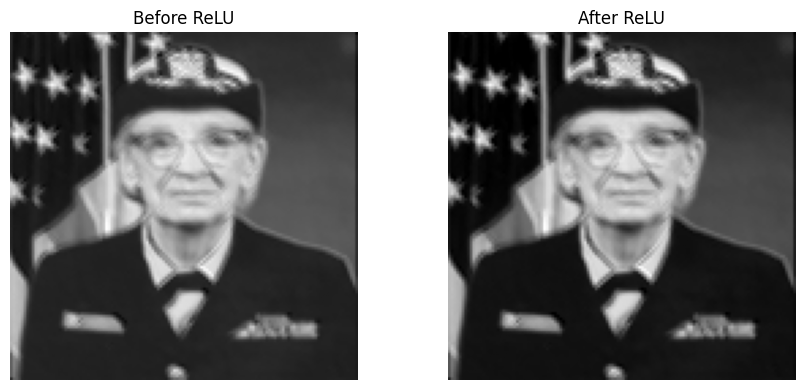

In [ ]:
# DEMO - use one random feature map.
pre_relu = random_maps[0, 0].detach()
post_relu = F.relu(pre_relu)

print('Before ReLU: min =', float(pre_relu.min()), 'max =', float(pre_relu.max()))
print('After  ReLU: min =', float(post_relu.min()), 'max =', float(post_relu.max()))
print('Negative values before:', int((pre_relu < 0).sum()))
print('Negative values after :', int((post_relu < 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(pre_relu.numpy(), cmap='gray')
axes[0].set_title('Before ReLU')
axes[1].imshow(post_relu.numpy(), cmap='gray')
axes[1].set_title('After ReLU')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 7. Max pooling: calculate it manually, then verify

For each pooling window, max pooling keeps the strongest value.

In [ ]:
# DEMO - a 4×4 feature map.
pool_input = torch.tensor([
    [1., 3., 2., 0.],
    [4., 6., 1., 2.],
    [0., 2., 8., 3.],
    [1., 5., 4., 7.],
])
print(pool_input)

tensor([[1., 3., 2., 0.],
        [4., 6., 1., 2.],
        [0., 2., 8., 3.],
        [1., 5., 4., 7.]])


### PREDICT
Using 2×2 max pooling with stride 2, calculate the resulting 2×2 output by hand.

In [ ]:
pool = nn.MaxPool2d(kernel_size=2, stride=2)
pool_output = pool(pool_input.unsqueeze(0).unsqueeze(0)).squeeze()
print('Max-pooled output:\n', pool_output)

Max-pooled output:
 tensor([[6., 2.],
        [5., 8.]])


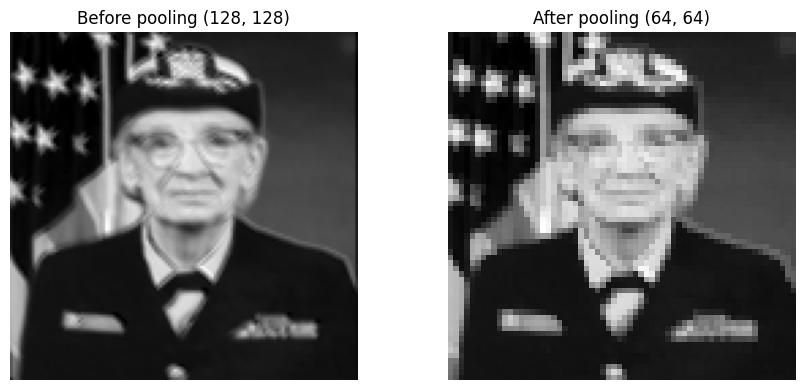

In [ ]:
# DEMO - pooling on a real activation map.
real_before = post_relu.unsqueeze(0).unsqueeze(0)
real_after = pool(real_before)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(real_before.squeeze().numpy(), cmap='gray')
axes[0].set_title(f'Before pooling {tuple(real_before.shape[-2:])}')
axes[1].imshow(real_after.squeeze().numpy(), cmap='gray')
axes[1].set_title(f'After pooling {tuple(real_after.shape[-2:])}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### CHECKPOINT
Pooling reduces spatial resolution. What useful information might this preserve, and what spatial detail might it discard?


It preserves the most prominet features. It disregards fine grained spatial details and exact positional information within each pooling window

---
# PART B - MNIST: UNDERSTAND CNN TRAINING STEP BY STEP

## 8. MNIST baseline: inspect the dataset before modelling

MNIST contains small 28×28 grayscale images of handwritten digits. It is deliberately simple enough that we can slow down and inspect training mechanics carefully.

To keep the comparison with MobileNet manageable, we use a fixed **12,000-image training subset and 2,000-image validation subset**. The exact same indices are reused later in the MNIST transfer-learning experiment.

In [ ]:
# INTERNET REQUIRED - MNIST downloads automatically on first run.
MNIST_TRAIN_N = 12_000
MNIST_VAL_N = 2_000
MNIST_BATCH_SIZE = 128

mnist_transform = transforms.ToTensor()
mnist_all_basic = datasets.MNIST(DATA_ROOT / 'mnist', train=True, download=True, transform=mnist_transform)
mnist_test_basic = datasets.MNIST(DATA_ROOT / 'mnist', train=False, download=True, transform=mnist_transform)

perm = torch.randperm(len(mnist_all_basic), generator=torch.Generator().manual_seed(SEED)).tolist()
mnist_train_idx = perm[:MNIST_TRAIN_N]
mnist_val_idx = perm[MNIST_TRAIN_N:MNIST_TRAIN_N + MNIST_VAL_N]

mnist_train = Subset(mnist_all_basic, mnist_train_idx)
mnist_val = Subset(mnist_all_basic, mnist_val_idx)

mnist_train_loader = DataLoader(mnist_train, batch_size=MNIST_BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
mnist_val_loader = DataLoader(mnist_val, batch_size=MNIST_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
mnist_test_loader = DataLoader(mnist_test_basic, batch_size=256, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

print('Training examples  :', len(mnist_train))
print('Validation examples:', len(mnist_val))
print('Test examples      :', len(mnist_test_basic))

100%|██████████| 9.91M/9.91M [00:00<00:00, 57.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.50MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.65MB/s]

Training examples  : 12000
Validation examples: 2000
Test examples      : 10000


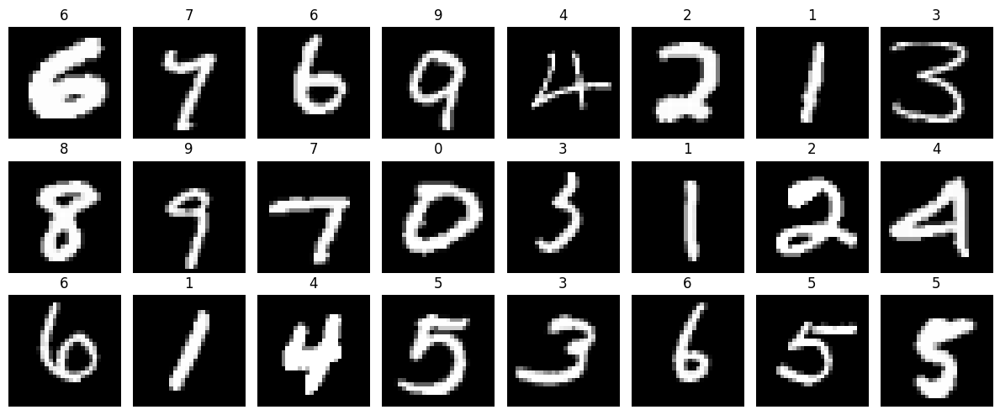

One image shape: (1, 28, 28)
dtype: torch.float32
range: 0.0 to 1.0


In [ ]:
# DEMO - preview MNIST.
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax, idx in zip(axes.flat, range(24)):
    image, label = mnist_train[idx]
    ax.imshow(image.squeeze(0), cmap='gray')
    ax.set_title(str(label))
    ax.axis('off')
plt.tight_layout()
plt.show()

sample_x, sample_y = mnist_train[0]
print('One image shape:', tuple(sample_x.shape))
print('dtype:', sample_x.dtype)
print('range:', float(sample_x.min()), 'to', float(sample_x.max()))

### CHECKPOINT
Compared with natural photographs, why is MNIST relatively easy?

MNIST images are of low resolution, the images are of gray scale

Consider resolution, number of channels, backgrounds, object pose, clutter, and number of classes.

## 9. Build a small CNN from scratch

We will use a deliberately understandable architecture:

`Conv → ReLU → Pool → Conv → ReLU → Pool → Conv → ReLU → Flatten → Linear`

In [ ]:
class SmallMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(64 * 7 * 7, 10)

    def feature_maps(self, x):
        a1 = F.relu(self.conv1(x))       # B×16×28×28
        p1 = self.pool(a1)               # B×16×14×14
        a2 = F.relu(self.conv2(p1))      # B×32×14×14
        p2 = self.pool(a2)               # B×32×7×7
        a3 = F.relu(self.conv3(p2))      # B×64×7×7
        return {'conv1': a1, 'pool1': p1, 'conv2': a2, 'pool2': p2, 'conv3': a3}

    def forward(self, x):
        feats = self.feature_maps(x)
        x = feats['conv3'].flatten(1)
        return self.fc(x)

mnist_model = SmallMNISTCNN().to(DEVICE)
mnist_initial_state = copy.deepcopy(mnist_model.state_dict())

print(mnist_model)
trainable_params = sum(p.numel() for p in mnist_model.parameters() if p.requires_grad)
print(f'Trainable parameters: {trainable_params:,}')

SmallMNISTCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=3136, out_features=10, bias=True)
)
Trainable parameters: 54,666


## 10. Trace one batch through the CNN

Before training, verify the tensor transformations. A CNN architecture is easier to understand when you can state the tensor shape at each stage.

In [ ]:
images, labels = next(iter(mnist_train_loader))
images = images.to(DEVICE)

with torch.no_grad():
    feats = mnist_model.feature_maps(images[:4])
    logits = mnist_model(images[:4])

print('Input :', tuple(images[:4].shape))
for name, value in feats.items():
    print(f'{name:6s}:', tuple(value.shape))
print('Logits:', tuple(logits.shape))

Input : (4, 1, 28, 28)
conv1 : (4, 16, 28, 28)
pool1 : (4, 16, 14, 14)
conv2 : (4, 32, 14, 14)
pool2 : (4, 32, 7, 7)
conv3 : (4, 64, 7, 7)
Logits: (4, 10)


### CHECKPOINT
Explain:
1. why channel count increases from 1 → 16 → 32 → 64;
2. why spatial dimensions shrink after pooling;
3. why the final output has 10 values per image.

## 11. The most important training cell: one batch, completely unpacked

A full training loop repeats the same basic sequence many times:

**forward pass → loss → clear gradients → backward pass → parameter update**

We will execute it once manually and inspect the evidence.

In [ ]:
# Reset to the original untrained state so the demonstration starts cleanly.
mnist_model.load_state_dict(mnist_initial_state)
mnist_model.to(DEVICE)
mnist_model.train()

criterion = nn.CrossEntropyLoss()
mnist_optimizer = torch.optim.Adam(mnist_model.parameters(), lr=1e-3)

one_batch_images, one_batch_labels = next(iter(mnist_train_loader))
one_batch_images = one_batch_images.to(DEVICE)
one_batch_labels = one_batch_labels.to(DEVICE)

print('Images:', tuple(one_batch_images.shape))
print('Labels:', tuple(one_batch_labels.shape))
print('First 12 labels:', one_batch_labels[:12].tolist())

Images: (128, 1, 28, 28)
Labels: (128,)
First 12 labels: [5, 8, 9, 5, 8, 1, 0, 1, 6, 6, 3, 8]


In [ ]:
# STEP A - forward pass.
logits = mnist_model(one_batch_images)
predictions = logits.argmax(dim=1)

print('Logit tensor shape:', tuple(logits.shape))
print('First 12 untrained predictions:', predictions[:12].tolist())
print('First 12 true labels          :', one_batch_labels[:12].tolist())

Logit tensor shape: (128, 10)
First 12 untrained predictions: [2, 3, 3, 7, 3, 3, 2, 3, 3, 2, 2, 3]
First 12 true labels          : [5, 8, 9, 5, 8, 1, 0, 1, 6, 6, 3, 8]


In [ ]:
# STEP B - calculate loss.
loss = criterion(logits, one_batch_labels)
print('Cross-entropy loss:', float(loss.item()))

Cross-entropy loss: 2.2999863624572754


In [ ]:
# STEP C - clear old gradients, then backpropagate.
mnist_optimizer.zero_grad()
loss.backward()

grad = mnist_model.conv1.weight.grad.detach()
print('conv1 gradient shape:', tuple(grad.shape))
print('Gradient mean:', float(grad.mean()))
print('Gradient std :', float(grad.std()))
print('Gradient min/max:', float(grad.min()), float(grad.max()))

conv1 gradient shape: (16, 1, 3, 3)
Gradient mean: 5.2983152272645384e-05
Gradient std : 0.0008675892604514956
Gradient min/max: -0.002192172920331359 0.0025593480095267296


Maximum absolute change in filter 0: 0.0009999871253967285
Mean absolute change in filter 0   : 0.0009999589528888464


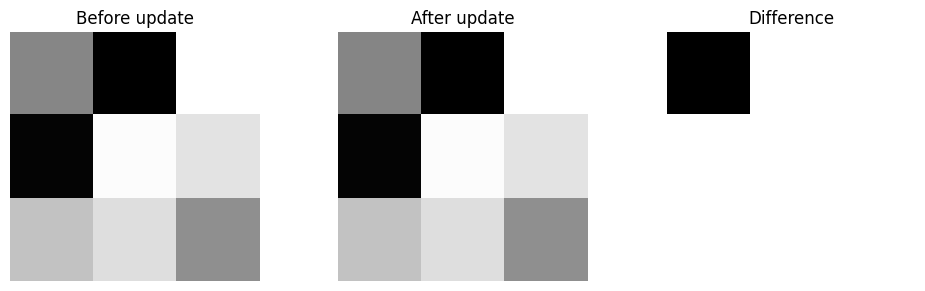

In [ ]:
# STEP D - prove that an optimizer update changes a convolution filter.
filter_before_update = mnist_model.conv1.weight[0].detach().clone()
mnist_optimizer.step()
filter_after_update = mnist_model.conv1.weight[0].detach().clone()
filter_delta = filter_after_update - filter_before_update

print('Maximum absolute change in filter 0:', float(filter_delta.abs().max()))
print('Mean absolute change in filter 0   :', float(filter_delta.abs().mean()))

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(filter_before_update.squeeze().cpu(), cmap='gray')
axes[0].set_title('Before update')
axes[1].imshow(filter_after_update.squeeze().cpu(), cmap='gray')
axes[1].set_title('After update')
axes[2].imshow(filter_delta.squeeze().cpu(), cmap='gray')
axes[2].set_title('Difference')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### CHECKPOINT - evidence that filters are learned
The convolution filter changed after `loss.backward()` produced gradients and `optimizer.step()` used those gradients.

Explain, in your own words, why this is stronger evidence than merely saying “CNNs learn filters.”

## 12. Reusable training and evaluation utilities

Now that the single optimization step is understood, we can safely automate repetition across batches and epochs.

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += images.size(0)

    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += images.size(0)

    return running_loss / total, correct / total

@torch.no_grad()
def preview_predictions(model, loader, device, n=8):
    model.eval()
    images, labels = next(iter(loader))
    images_device = images.to(device)
    probs = F.softmax(model(images_device), dim=1).cpu()
    preds = probs.argmax(dim=1)
    conf = probs.max(dim=1).values
    return images[:n].cpu(), labels[:n].cpu(), preds[:n], conf[:n]

def fit_model(model, train_loader, val_loader, criterion, optimizer, device, epochs,
              snapshot_loader=None, snapshot_epochs=()):
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'epoch_seconds': []}
    snapshots = {}
    overall_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)
        elapsed = time.perf_counter() - start

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['epoch_seconds'].append(elapsed)

        print(
            f'Epoch {epoch:02d}/{epochs} | '
            f'train loss {train_loss:.4f} acc {train_acc:.3%} | '
            f'val loss {val_loss:.4f} acc {val_acc:.3%} | '
            f'{elapsed:.1f}s'
        )

        if snapshot_loader is not None and epoch in snapshot_epochs:
            snapshots[epoch] = preview_predictions(model, snapshot_loader, device)

    history['total_seconds'] = time.perf_counter() - overall_start
    return history, snapshots

def plot_history(history, title='Training history'):
    epochs = np.arange(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history['train_loss'], marker='o', label='Train loss')
    plt.plot(epochs, history['val_loss'], marker='o', label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(title + ' - loss')
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history['train_acc'], marker='o', label='Train accuracy')
    plt.plot(epochs, history['val_acc'], marker='o', label='Validation accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(title + ' - accuracy')
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

## 13. Full MNIST training

This is our first complete CNN training run. Because the dataset and model are small, it should finish quickly on Colab. **Record the runtime your own session reports rather than assuming a fixed time.**

Epoch 01/5 | train loss 0.7474 acc 77.483% | val loss 0.2431 acc 92.800% | 2.2s
Epoch 02/5 | train loss 0.2129 acc 93.508% | val loss 0.1374 acc 96.000% | 2.5s
Epoch 03/5 | train loss 0.1299 acc 96.175% | val loss 0.0978 acc 97.000% | 1.8s
Epoch 04/5 | train loss 0.0931 acc 97.250% | val loss 0.0924 acc 97.600% | 1.8s
Epoch 05/5 | train loss 0.0753 acc 97.683% | val loss 0.0763 acc 97.900% | 1.9s

MNIST test accuracy: 97.740%
Total MNIST training time: 10.1s


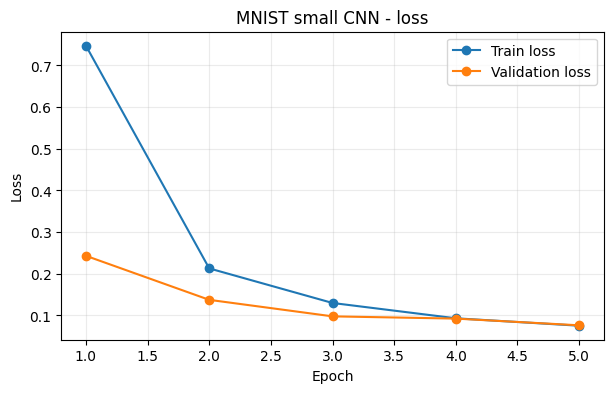

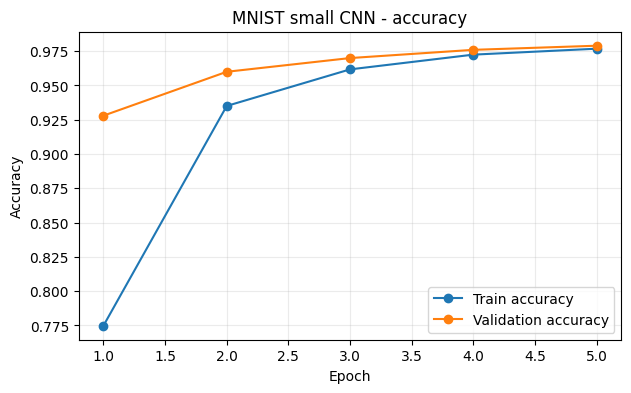

In [ ]:
# LONG-RUNNING DEMO - typically short on a Colab GPU.
MNIST_EPOCHS = 5

# Start again from the original initialization so our recorded experiment is reproducible.
mnist_model.load_state_dict(mnist_initial_state)
mnist_model.to(DEVICE)
mnist_optimizer = torch.optim.Adam(mnist_model.parameters(), lr=1e-3)

mnist_history, _ = fit_model(
    mnist_model,
    mnist_train_loader,
    mnist_val_loader,
    criterion,
    mnist_optimizer,
    DEVICE,
    epochs=MNIST_EPOCHS,
)

mnist_test_loss, mnist_test_acc = evaluate(mnist_model, mnist_test_loader, criterion, DEVICE)
print(f'\nMNIST test accuracy: {mnist_test_acc:.3%}')
print(f'Total MNIST training time: {mnist_history["total_seconds"]:.1f}s')
plot_history(mnist_history, 'MNIST small CNN')

## 14. Watch the internal representation change: before vs after training

We will pass the **same digit** through:

1. a model with the original random initialization; and
2. the trained model.

The point is not that every learned map becomes human-readable. The point is that training changes the responses and creates representations useful for the task.

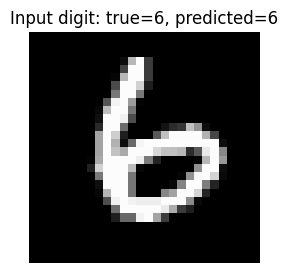

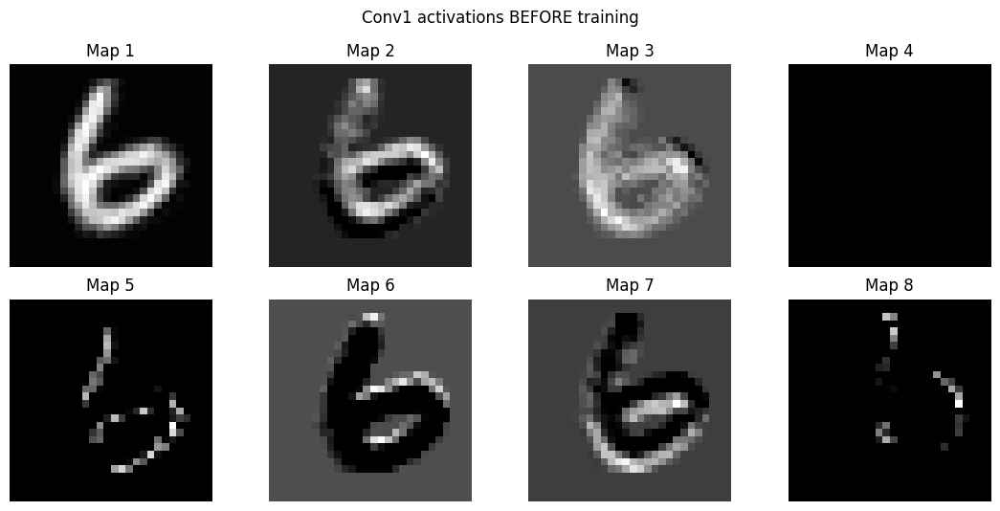

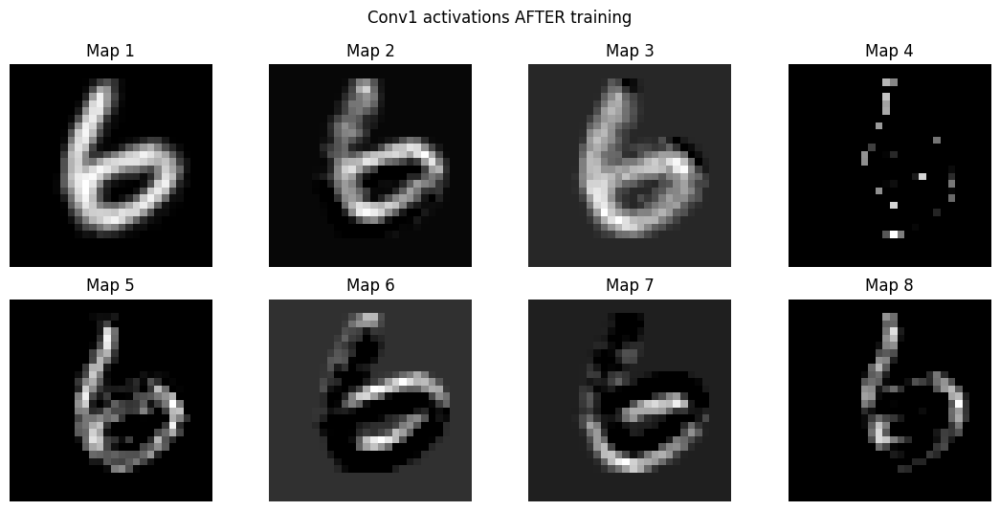

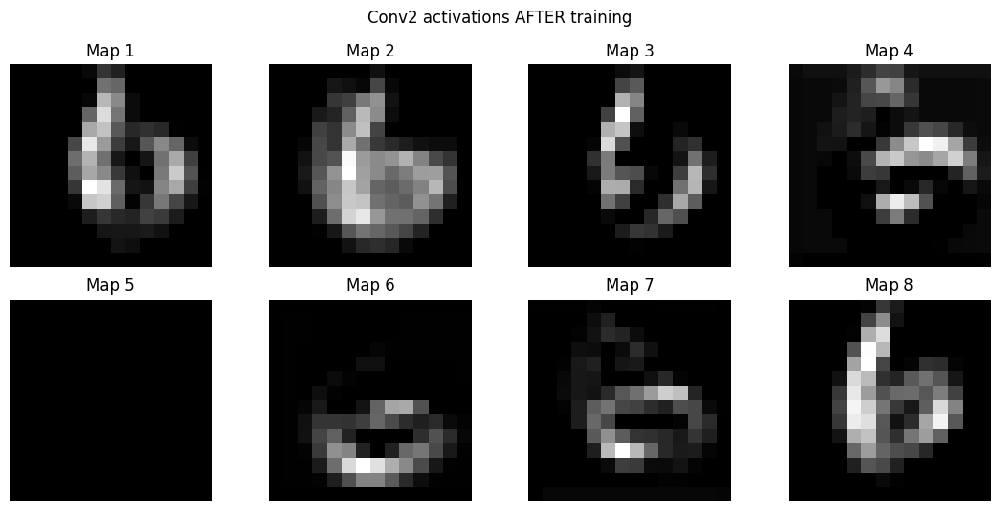

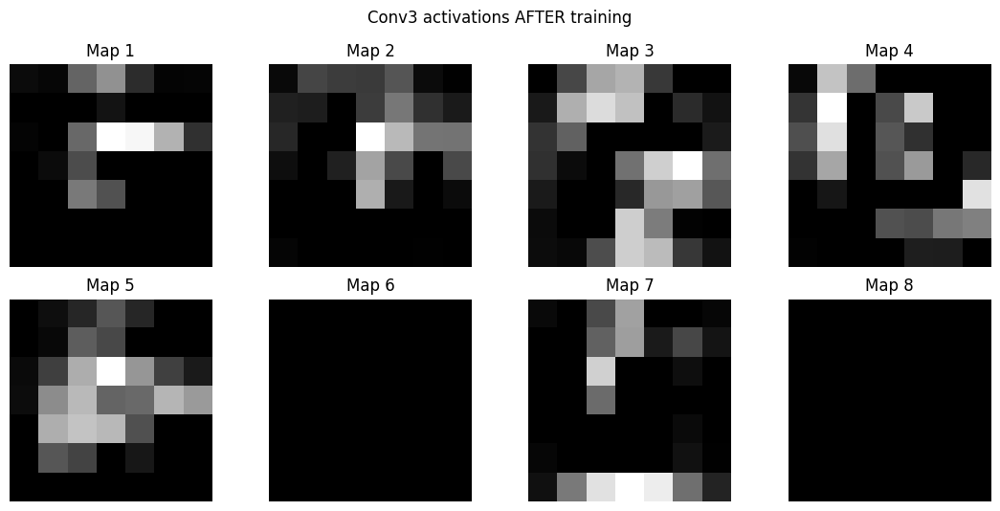

In [ ]:
def show_feature_maps(feature_tensor, title, max_maps=8):
    maps = feature_tensor.detach().cpu()[0]
    n = min(max_maps, maps.shape[0])
    cols = 4
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(11, 2.7 * rows))
    axes = np.array(axes).reshape(-1)
    for i in range(n):
        axes[i].imshow(maps[i], cmap='gray')
        axes[i].set_title(f'Map {i+1}')
        axes[i].axis('off')
    for i in range(n, len(axes)):
        axes[i].axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

mnist_untrained = SmallMNISTCNN().to(DEVICE)
mnist_untrained.load_state_dict(mnist_initial_state)
mnist_untrained.eval()
mnist_model.eval()

example_image, example_label = mnist_val[0]
example_batch = example_image.unsqueeze(0).to(DEVICE)

with torch.no_grad():
    before_feats = mnist_untrained.feature_maps(example_batch)
    after_feats = mnist_model.feature_maps(example_batch)
    after_pred = mnist_model(example_batch).argmax(dim=1).item()

plt.figure(figsize=(3, 3))
plt.imshow(example_image.squeeze(), cmap='gray')
plt.title(f'Input digit: true={example_label}, predicted={after_pred}')
plt.axis('off')
plt.show()

show_feature_maps(before_feats['conv1'], 'Conv1 activations BEFORE training')
show_feature_maps(after_feats['conv1'], 'Conv1 activations AFTER training')
show_feature_maps(after_feats['conv2'], 'Conv2 activations AFTER training')
show_feature_maps(after_feats['conv3'], 'Conv3 activations AFTER training')

### CHECKPOINT - pixels to useful representations
A helpful conceptual summary is:

**pixels → local transitions/strokes → combinations of local patterns → task-relevant representation → class scores**

Do **not** assume that every deep feature map corresponds to a neat human concept such as “loop” or “top of an 8.” Deep representations are often distributed across many channels.

## 15. Visualize learned first-layer filters

The first MNIST convolution has 16 grayscale 3×3 filters. We can compare the exact parameter values before and after training.

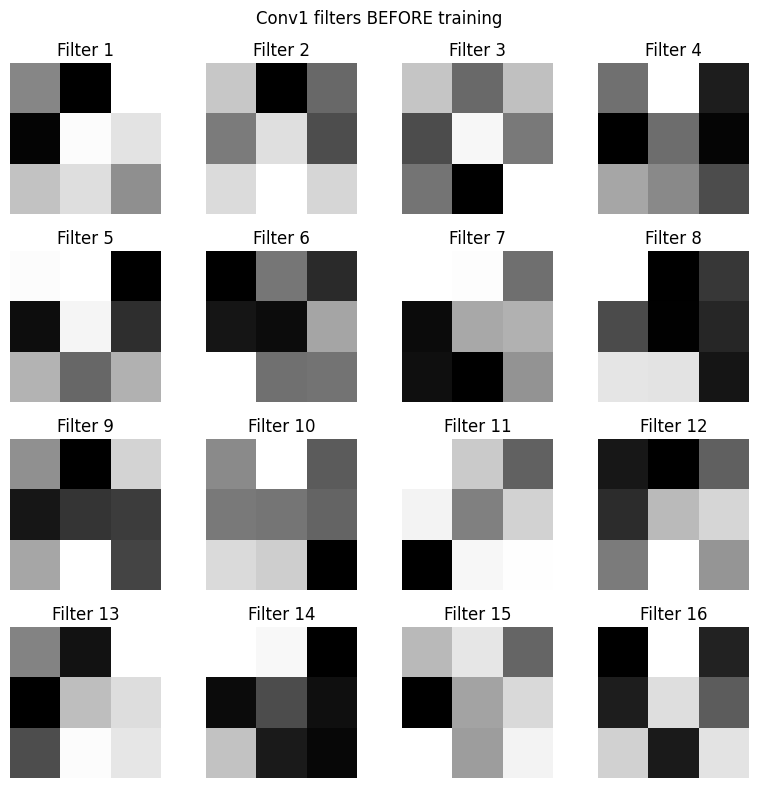

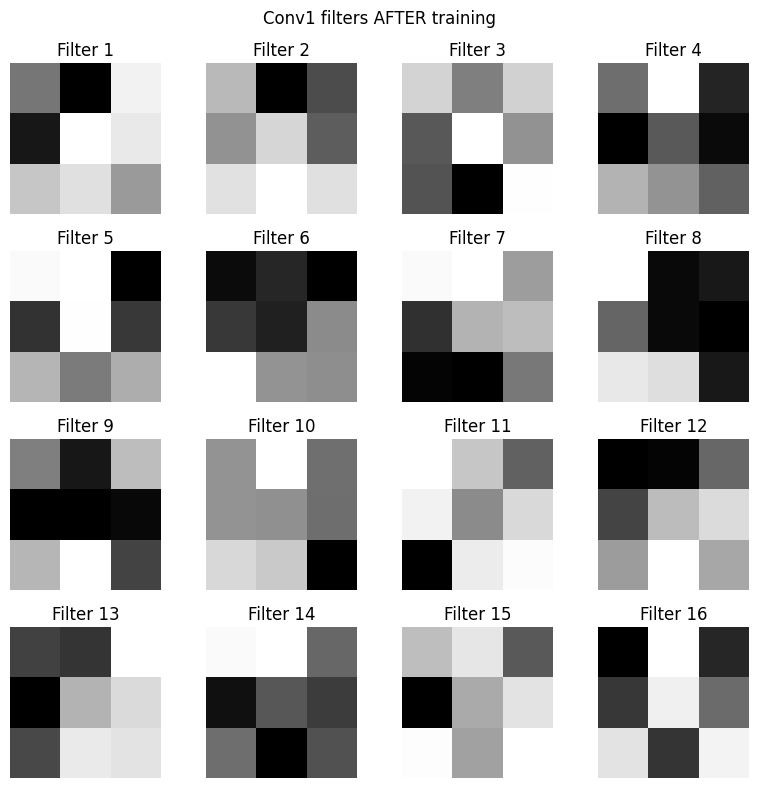

In [ ]:
def show_conv1_filters(state_dict_or_model, title, max_filters=16):
    if isinstance(state_dict_or_model, nn.Module):
        weights = state_dict_or_model.conv1.weight.detach().cpu()
    else:
        weights = state_dict_or_model['conv1.weight'].detach().cpu()

    n = min(max_filters, weights.shape[0])
    cols = 4
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(8, 2 * rows))
    axes = np.array(axes).reshape(-1)
    for i in range(n):
        axes[i].imshow(weights[i, 0], cmap='gray')
        axes[i].set_title(f'Filter {i+1}')
        axes[i].axis('off')
    for i in range(n, len(axes)):
        axes[i].axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_conv1_filters(mnist_initial_state, 'Conv1 filters BEFORE training')
show_conv1_filters(mnist_model, 'Conv1 filters AFTER training')

## 16. Error analysis: a strong accuracy still contains mistakes

Accuracy alone hides *which* examples fail. We will collect predictions, build a confusion matrix, and inspect high-confidence errors.

In [ ]:
@torch.no_grad()
def collect_predictions(model, loader, device, keep_images=True):
    model.eval()
    all_images, all_labels, all_preds, all_conf = [], [], [], []
    for images, labels in loader:
        logits = model(images.to(device))
        probs = F.softmax(logits, dim=1).cpu()
        preds = probs.argmax(dim=1)
        conf = probs.max(dim=1).values
        if keep_images:
            all_images.append(images.cpu())
        all_labels.append(labels.cpu())
        all_preds.append(preds)
        all_conf.append(conf)
    images_out = torch.cat(all_images) if keep_images else None
    return (
        images_out,
        torch.cat(all_labels),
        torch.cat(all_preds),
        torch.cat(all_conf),
    )

def confusion_matrix_torch(labels, preds, num_classes):
    cm = torch.zeros((num_classes, num_classes), dtype=torch.int64)
    for t, p in zip(labels.view(-1), preds.view(-1)):
        cm[int(t), int(p)] += 1
    return cm

def plot_confusion_matrix(cm, class_names, title='Confusion matrix'):
    plt.figure(figsize=(7, 6))
    plt.imshow(cm.numpy(), cmap='Blues')
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.xticks(range(len(class_names)), class_names, rotation=45)
    plt.yticks(range(len(class_names)), class_names)
    plt.colorbar()
    if len(class_names) <= 10:
        threshold = cm.max().item() * 0.55
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                color = 'white' if cm[i, j].item() > threshold else 'black'
                plt.text(j, i, str(cm[i, j].item()), ha='center', va='center', color=color, fontsize=8)
    plt.tight_layout()
    plt.show()

def show_prediction_examples(images, labels, preds, conf, class_names, indices, title, denorm_fn=None):
    indices = list(indices)
    cols = 4
    rows = math.ceil(len(indices) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(13, 3.3 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, idx in zip(axes, indices):
        img = images[idx]
        if denorm_fn is not None:
            img = denorm_fn(img)
        if img.shape[0] == 1:
            ax.imshow(img.squeeze(0), cmap='gray')
        else:
            ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
        ax.set_title(
            f'True: {class_names[int(labels[idx])]}\n'
            f'Pred: {class_names[int(preds[idx])]} ({float(conf[idx]):.1%})'
        )
        ax.axis('off')
    for ax in axes[len(indices):]:
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

def show_dataset_prediction_examples(dataset, labels, preds, conf, class_names, indices, title, denorm_fn=None):
    indices = [int(i) for i in indices]
    cols = 4
    rows = math.ceil(len(indices) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(13, 3.3 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, idx in zip(axes, indices):
        img, _ = dataset[idx]
        if denorm_fn is not None:
            img = denorm_fn(img)
        if img.shape[0] == 1:
            ax.imshow(img.squeeze(0), cmap='gray')
        else:
            ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
        ax.set_title(
            f'True: {class_names[int(labels[idx])]}\n'
            f'Pred: {class_names[int(preds[idx])]} ({float(conf[idx]):.1%})'
        )
        ax.axis('off')
    for ax in axes[len(indices):]:
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

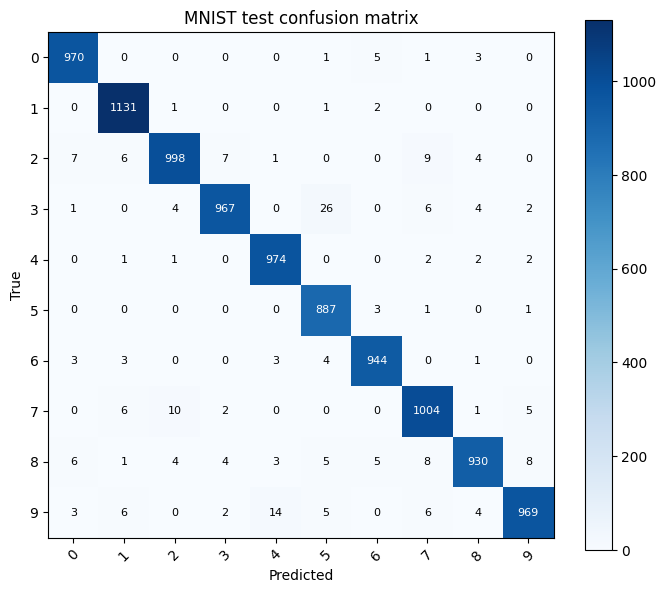

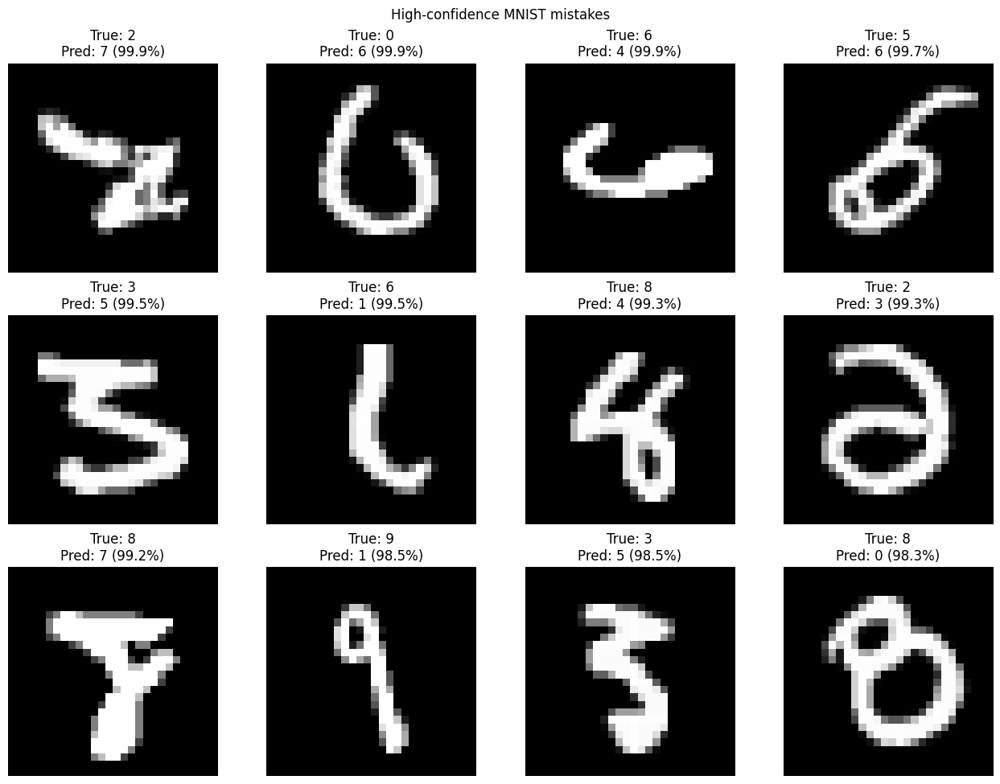

In [ ]:
mnist_images_all, mnist_labels_all, mnist_preds_all, mnist_conf_all = collect_predictions(mnist_model, mnist_test_loader, DEVICE)
mnist_cm = confusion_matrix_torch(mnist_labels_all, mnist_preds_all, 10)
plot_confusion_matrix(mnist_cm, [str(i) for i in range(10)], 'MNIST test confusion matrix')

wrong = torch.where(mnist_labels_all != mnist_preds_all)[0]
if len(wrong) > 0:
    top_wrong = wrong[torch.argsort(mnist_conf_all[wrong], descending=True)[:12]]
    show_prediction_examples(
        mnist_images_all, mnist_labels_all, mnist_preds_all, mnist_conf_all,
        [str(i) for i in range(10)], top_wrong,
        'High-confidence MNIST mistakes'
    )
else:
    print('No test errors found in this run.')

### CHECKPOINT
A softmax confidence such as 95% is **not proof** that a prediction is correct. It is a property of the model's output distribution, not an external guarantee of truth.

What patterns do you notice among the incorrect digits?

---
# PART C - MNIST TRANSFER LEARNING: WHEN A BIG PRETRAINED MODEL IS OVERKILL

## 17. Force MNIST into MobileNetV2's world

MobileNetV2 was pretrained on natural RGB ImageNet photographs. MNIST is 28×28 grayscale handwriting.

To reuse MobileNetV2, we deliberately transform each MNIST digit into a larger 3-channel image. This adds computation but **does not create new visual information**.

The experiment is not designed to guarantee that MobileNet performs worse. It asks a better engineering question:

> Does a much larger pretrained natural-image model provide enough benefit to justify its additional complexity on this very simple task?

In [ ]:
# INTERNET REQUIRED - pretrained ImageNet weights download on first use.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

mnist_mobile_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

mnist_all_mobile = datasets.MNIST(DATA_ROOT / 'mnist', train=True, download=True, transform=mnist_mobile_transform)
mnist_test_mobile = datasets.MNIST(DATA_ROOT / 'mnist', train=False, download=True, transform=mnist_mobile_transform)

mnist_train_mobile = Subset(mnist_all_mobile, mnist_train_idx)
mnist_val_mobile = Subset(mnist_all_mobile, mnist_val_idx)

mnist_mobile_train_loader = DataLoader(mnist_train_mobile, batch_size=64, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
mnist_mobile_val_loader = DataLoader(mnist_val_mobile, batch_size=128, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
mnist_mobile_test_loader = DataLoader(mnist_test_mobile, batch_size=128, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

weights = MobileNet_V2_Weights.DEFAULT
mnist_mobile_model = mobilenet_v2(weights=weights)
for p in mnist_mobile_model.features.parameters():
    p.requires_grad = False
mnist_mobile_model.classifier[1] = nn.Linear(mnist_mobile_model.classifier[1].in_features, 10)
mnist_mobile_model = mnist_mobile_model.to(DEVICE)

print('Total parameters    :', f'{sum(p.numel() for p in mnist_mobile_model.parameters()):,}')
print('Trainable parameters:', f'{sum(p.numel() for p in mnist_mobile_model.parameters() if p.requires_grad):,}')

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 116MB/s] 

Total parameters    : 2,236,682
Trainable parameters: 12,810


In [ ]:
# LONG-RUNNING DEMO - frozen MobileNet feature extraction on MNIST.
MNIST_MOBILE_EPOCHS = 3
mnist_mobile_optimizer = torch.optim.Adam(
    [p for p in mnist_mobile_model.parameters() if p.requires_grad], lr=1e-3
)

mnist_mobile_history, _ = fit_model(
    mnist_mobile_model,
    mnist_mobile_train_loader,
    mnist_mobile_val_loader,
    criterion,
    mnist_mobile_optimizer,
    DEVICE,
    epochs=MNIST_MOBILE_EPOCHS,
)
mnist_mobile_test_loss, mnist_mobile_test_acc = evaluate(
    mnist_mobile_model, mnist_mobile_test_loader, criterion, DEVICE
)

print(f'\nMobileNet MNIST test accuracy: {mnist_mobile_test_acc:.3%}')
print(f'Total MobileNet MNIST training time: {mnist_mobile_history["total_seconds"]:.1f}s')

Epoch 01/3 | train loss 1.0093 acc 73.917% | val loss 0.5552 acc 86.300% | 13.5s
Epoch 02/3 | train loss 0.5235 acc 85.817% | val loss 0.4168 acc 88.600% | 12.8s
Epoch 03/3 | train loss 0.4232 acc 88.000% | val loss 0.3648 acc 89.900% | 15.2s

MobileNet MNIST test accuracy: 89.280%
Total MobileNet MNIST training time: 41.6s


In [ ]:
mnist_comparison = pd.DataFrame([
    {
        'Approach': 'Small CNN from scratch',
        'Test accuracy': mnist_test_acc,
        'Epochs': MNIST_EPOCHS,
        'Training seconds': mnist_history['total_seconds'],
        'Seconds/epoch': mnist_history['total_seconds'] / MNIST_EPOCHS,
        'Trainable parameters': sum(p.numel() for p in mnist_model.parameters() if p.requires_grad),
        'Input': '1×28×28',
    },
    {
        'Approach': 'Frozen MobileNetV2',
        'Test accuracy': mnist_mobile_test_acc,
        'Epochs': MNIST_MOBILE_EPOCHS,
        'Training seconds': mnist_mobile_history['total_seconds'],
        'Seconds/epoch': mnist_mobile_history['total_seconds'] / MNIST_MOBILE_EPOCHS,
        'Trainable parameters': sum(p.numel() for p in mnist_mobile_model.parameters() if p.requires_grad),
        'Input': '3×128×128',
    },
])
mnist_comparison

,Approach,Test accuracy,Epochs,Training seconds,Seconds/epoch,Trainable parameters,Input
0,Small CNN from scratch,0.9774,5,10.077017,2.015403,54666,1×28×28
1,Frozen MobileNetV2,0.8928,3,41.554593,13.851531,12810,3×128×128


## 18. Mid-lesson analysis: explain the MNIST inversion carefully

Possible reasons a pretrained MobileNet may add little value here:

1. **Task simplicity:** a small CNN already has enough capacity for MNIST.
2. **Domain mismatch:** ImageNet features were learned from natural RGB photographs, not handwritten grayscale strokes.
3. **Input mismatch:** 28×28×1 is expanded to 128×128×3. That increases computation without creating new information.
4. **Unnecessary capacity:** the engineering cost may be disproportionate to the problem.

### Core lesson
**Bigger and pretrained does not automatically mean better. Match the model to the task.**

Do not generalize this result into “transfer learning does not work.” The next experiment changes the visual complexity of the problem.

---
# PART D - NATURAL IMAGES: CATS VS DOGS FROM SCRATCH

## 19. Natural photographs change the problem

Cats-vs-dogs photographs contain much more variation than MNIST:

- pose and viewpoint;
- background clutter;
- lighting;
- scale;
- texture;
- occlusion;
- breed appearance;
- camera quality.

For this practical we use **Oxford-IIIT Pet** through `torchvision`. It contains real photographs of cats and dogs and provides a direct binary Cat/Dog target.

The setup cell below deliberately avoids a hand-written ZIP URL. It asks `torchvision` to manage the official dataset download and then prepares a balanced teaching subset in a standard folder structure.

### Reliability fallback

If the Oxford host is unavailable in a particular Colab session, the **same cell automatically falls back to the Cat and Dog classes from CIFAR-10**, which is downloaded by `torchvision` from a different host.

You should therefore run the setup cell **once** and allow it to select the available source automatically. The rest of the notebook uses the same `train_dir` and `val_dir` variables regardless of which source was selected.


In [ ]:
# INTERNET REQUIRED - robust natural-image dataset setup.
#
# Primary source:
#   Oxford-IIIT Pet through torchvision, using the built-in binary Cat/Dog target.
#
# Automatic fallback:
#   CIFAR-10 Cat/Dog subset through torchvision from a different host.
#
# Both routes are converted into exactly the same ImageFolder structure so that
# every later cell in the notebook works unchanged.

import shutil

CATS_DOGS_ROOT = DATA_ROOT / 'cats_dogs_ready'
train_dir = CATS_DOGS_ROOT / 'train'
val_dir = CATS_DOGS_ROOT / 'validation'

TRAIN_PER_CLASS = 1000
VAL_PER_CLASS = 500
CLASS_FOLDER = {0: 'cats', 1: 'dogs'}


def _folder_image_count(folder):
    if not folder.exists():
        return 0
    valid_ext = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    return sum(
        1 for p in folder.rglob('*')
        if p.is_file() and p.suffix.lower() in valid_ext
    )


def prepared_dataset_is_valid():
    expected = {
        train_dir / 'cats': TRAIN_PER_CLASS,
        train_dir / 'dogs': TRAIN_PER_CLASS,
        val_dir / 'cats': VAL_PER_CLASS,
        val_dir / 'dogs': VAL_PER_CLASS,
    }
    return all(_folder_image_count(folder) >= minimum for folder, minimum in expected.items())


def _prepare_empty_folders():
    if CATS_DOGS_ROOT.exists():
        shutil.rmtree(CATS_DOGS_ROOT)

    for split_dir in (train_dir, val_dir):
        for class_name in ('cats', 'dogs'):
            (split_dir / class_name).mkdir(parents=True, exist_ok=True)


def _balanced_indices(labels, per_class, seed):
    """Choose a reproducible balanced subset without depending on dataset order."""
    rng = random.Random(seed)
    chosen = []

    for class_id in (0, 1):
        candidates = [i for i, label in enumerate(labels) if int(label) == class_id]

        if len(candidates) < per_class:
            raise RuntimeError(
                f'Not enough examples for class {class_id}: '
                f'need {per_class}, found {len(candidates)}.'
            )

        rng.shuffle(candidates)
        chosen.extend(candidates[:per_class])

    rng.shuffle(chosen)
    return chosen


def _save_pil_as_jpeg(image, destination):
    """Save a clean RGB JPEG used by ImageFolder later."""
    image = image.convert('RGB')
    destination.parent.mkdir(parents=True, exist_ok=True)
    image.save(destination, format='JPEG', quality=92, optimize=False)


def _export_oxford_dataset(source_ds, destination_root, per_class, seed):
    # Oxford-IIIT Pet with target_types='binary-category' returns:
    # 0 = Cat, 1 = Dog.
    labels = []
    for i in range(len(source_ds)):
        _, label = source_ds[i]
        labels.append(int(label))

    indices = _balanced_indices(labels, per_class, seed)

    for out_number, idx in enumerate(indices):
        image, label = source_ds[idx]
        class_name = CLASS_FOLDER[int(label)]
        out_path = destination_root / class_name / f'oxford_{out_number:05d}.jpg'
        _save_pil_as_jpeg(image, out_path)


def _export_cifar_binary(source_ds, destination_root, per_class, seed):
    # CIFAR-10 labels:
    # 3 = cat, 5 = dog.
    cifar_to_binary = {3: 0, 5: 1}

    usable_indices = [
        i for i, label in enumerate(source_ds.targets)
        if int(label) in cifar_to_binary
    ]
    binary_labels = [cifar_to_binary[int(source_ds.targets[i])] for i in usable_indices]

    rng = random.Random(seed)
    selected_original_indices = []

    for binary_class in (0, 1):
        candidates = [
            original_idx
            for original_idx, label in zip(usable_indices, binary_labels)
            if label == binary_class
        ]

        if len(candidates) < per_class:
            raise RuntimeError(
                f'CIFAR-10 fallback does not have enough examples for class '
                f'{binary_class}: need {per_class}, found {len(candidates)}.'
            )

        rng.shuffle(candidates)
        selected_original_indices.extend(candidates[:per_class])

    rng.shuffle(selected_original_indices)

    for out_number, idx in enumerate(selected_original_indices):
        image, original_label = source_ds[idx]
        binary_label = cifar_to_binary[int(original_label)]
        class_name = CLASS_FOLDER[binary_label]
        out_path = destination_root / class_name / f'cifar_{out_number:05d}.jpg'
        _save_pil_as_jpeg(image, out_path)


def prepare_cats_dogs_dataset():
    """
    Prepare a balanced Cat/Dog dataset once.

    Route A: Oxford-IIIT Pet (preferred, real higher-resolution pet photographs)
    Route B: CIFAR-10 cat/dog subset (automatic fallback, different host)

    Returns the name of the source actually used.
    """
    if prepared_dataset_is_valid():
        print('Prepared Cats vs Dogs folders already exist. Reusing them.')
        return 'Previously prepared dataset'

    _prepare_empty_folders()

    # ---------- PRIMARY: Oxford-IIIT Pet ----------
    try:
        print('Primary source: Oxford-IIIT Pet via torchvision')
        print('Downloading/checking the official dataset...')

        oxford_root = DATA_ROOT / 'oxford_pet_source'

        oxford_train = datasets.OxfordIIITPet(
            root=oxford_root,
            split='trainval',
            target_types='binary-category',
            download=True,
        )
        oxford_val = datasets.OxfordIIITPet(
            root=oxford_root,
            split='test',
            target_types='binary-category',
            download=True,
        )

        print('Preparing balanced teaching subset...')
        _export_oxford_dataset(
            oxford_train, train_dir,
            per_class=TRAIN_PER_CLASS,
            seed=SEED,
        )
        _export_oxford_dataset(
            oxford_val, val_dir,
            per_class=VAL_PER_CLASS,
            seed=SEED + 1,
        )

        if not prepared_dataset_is_valid():
            raise RuntimeError('Oxford preparation finished but folder validation failed.')

        return 'Oxford-IIIT Pet'

    except Exception as oxford_error:
        print('\nOxford-IIIT Pet was unavailable in this runtime.')
        print('Reason:', type(oxford_error).__name__, '-', str(oxford_error)[:250])
        print('\nAutomatically switching to the CIFAR-10 Cat/Dog fallback...')
        _prepare_empty_folders()

    # ---------- FALLBACK: CIFAR-10 ----------
    try:
        cifar_root = DATA_ROOT / 'cifar10_source'

        cifar_train = datasets.CIFAR10(
            root=cifar_root,
            train=True,
            download=True,
        )
        cifar_val = datasets.CIFAR10(
            root=cifar_root,
            train=False,
            download=True,
        )

        print('Preparing balanced Cat/Dog teaching subset from CIFAR-10...')
        _export_cifar_binary(
            cifar_train, train_dir,
            per_class=TRAIN_PER_CLASS,
            seed=SEED,
        )
        _export_cifar_binary(
            cifar_val, val_dir,
            per_class=VAL_PER_CLASS,
            seed=SEED + 1,
        )

        if not prepared_dataset_is_valid():
            raise RuntimeError('CIFAR-10 preparation finished but folder validation failed.')

        return 'CIFAR-10 Cat/Dog fallback'

    except Exception as cifar_error:
        _prepare_empty_folders()
        raise RuntimeError(
            'Both independent torchvision dataset sources failed in this runtime. '
            'Oxford-IIIT Pet and CIFAR-10 are hosted separately, so this usually '
            'indicates that the runtime currently cannot reach external dataset hosts.'
        ) from cifar_error


DATASET_SOURCE = prepare_cats_dogs_dataset()

print('\nDataset source used:', DATASET_SOURCE)
print('Training directory :', train_dir)
print('Validation directory:', val_dir)
print('Train cats:', _folder_image_count(train_dir / 'cats'))
print('Train dogs:', _folder_image_count(train_dir / 'dogs'))
print('Val cats  :', _folder_image_count(val_dir / 'cats'))
print('Val dogs  :', _folder_image_count(val_dir / 'dogs'))

if 'CIFAR-10' in DATASET_SOURCE:
    print(
        '\nNOTE: The automatic fallback uses 32×32 natural images. '
        'The later transforms upscale them to the model input size. '
        'The notebook remains valid, although the transfer-learning advantage '
        'may be smaller than with Oxford-IIIT Pet.'
    )

print('\nDataset preparation complete. Continue to the next cell.')


Primary source: Oxford-IIIT Pet via torchvision
Downloading/checking the official dataset...


100%|██████████| 792M/792M [00:28<00:00, 27.9MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 19.3MB/s]


Preparing balanced teaching subset...

Dataset source used: Oxford-IIIT Pet
Training directory : /content/cv_cnn_data/cats_dogs_ready/train
Validation directory: /content/cv_cnn_data/cats_dogs_ready/validation
Train cats: 1000
Train dogs: 1000
Val cats  : 500
Val dogs  : 500

Dataset preparation complete. Continue to the next cell.


## 20. Define fair image preprocessing

Both the scratch CNN and MobileNet use the **same prepared Cat/Dog folders**, the same 160×160 model input size, and the same ImageNet normalization.

The training set receives mild augmentation; validation does not.

Because the setup cell standardizes either source into:

```text
train/cats
train/dogs
validation/cats
validation/dogs
```

all later `ImageFolder`, training, feature-map, Grad-CAM, and transfer-learning cells work unchanged.


In [ ]:
IMAGE_SIZE = 160
CATS_DOGS_BATCH = 32

cats_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.80, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

cats_val_transform = transforms.Compose([
    transforms.Resize((176, 176)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

cats_train_ds = datasets.ImageFolder(train_dir, transform=cats_train_transform)
cats_val_ds = datasets.ImageFolder(val_dir, transform=cats_val_transform)

cats_train_loader = DataLoader(cats_train_ds, batch_size=CATS_DOGS_BATCH, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
cats_val_loader = DataLoader(cats_val_ds, batch_size=CATS_DOGS_BATCH, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

print('Classes:', cats_train_ds.classes)
print('Training examples:', len(cats_train_ds))
print('Validation examples:', len(cats_val_ds))

Classes: ['cats', 'dogs']
Training examples: 2000
Validation examples: 1000


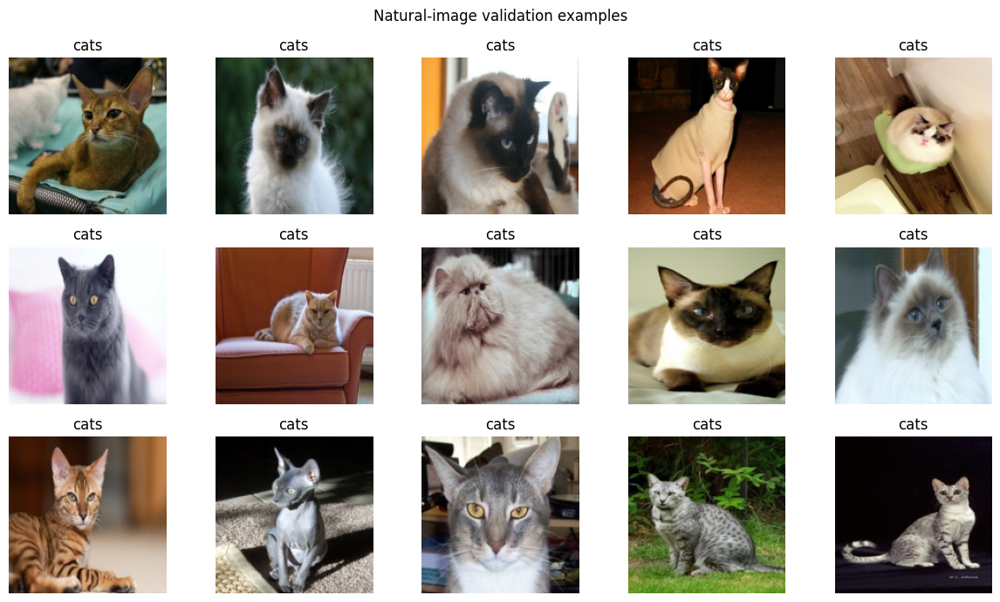

In [ ]:
# DEMO - helpers to undo ImageNet normalization for display.
def denormalize_imagenet(tensor):
    mean = torch.tensor(IMAGENET_MEAN, dtype=tensor.dtype).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD, dtype=tensor.dtype).view(3, 1, 1)
    return (tensor.cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(cats_val_loader))
fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for ax, image, label in zip(axes.flat, images[:15], labels[:15]):
    ax.imshow(denormalize_imagenet(image).permute(1, 2, 0))
    ax.set_title(cats_val_ds.classes[int(label)])
    ax.axis('off')
plt.suptitle('Natural-image validation examples')
plt.tight_layout()
plt.show()

### CHECKPOINT
Identify at least three sources of visual variation that were largely absent from MNIST.

Color, complex background,lighting conditions

## 21. Preview augmentation before training

Augmentation is only useful when the transformation is compatible with the label. A cat should remain a cat after a mild crop, flip, or colour change.

We will show multiple transformed versions of the **same original photograph**.

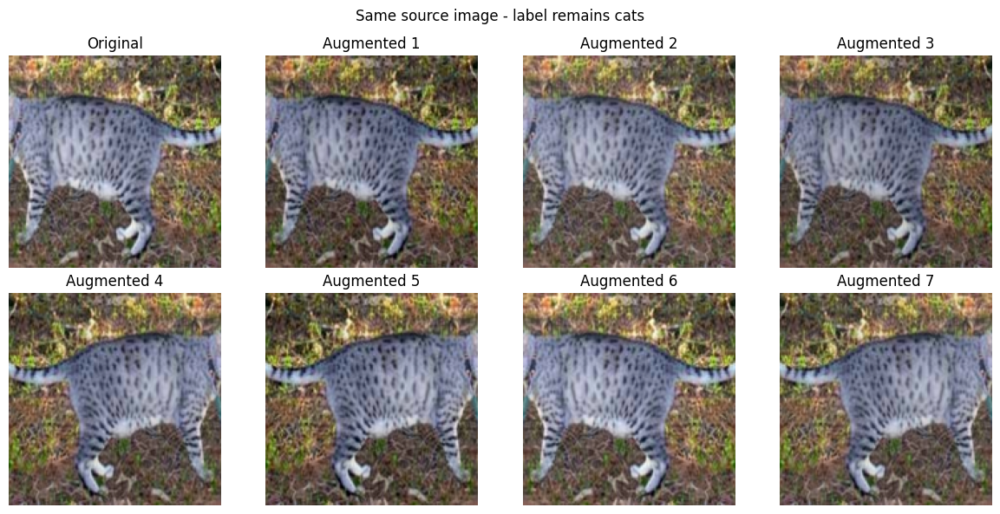

In [ ]:
# DEMO - repeatedly transform the same original file.
example_path, example_class = cats_train_ds.samples[0]
original_pil = Image.open(example_path).convert('RGB')

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    augmented = cats_train_transform(original_pil)
    ax.imshow(denormalize_imagenet(augmented).permute(1, 2, 0))
    ax.set_title('Original' if i == 0 else f'Augmented {i}')
    ax.axis('off')
plt.suptitle(f'Same source image - label remains {cats_train_ds.classes[example_class]}')
plt.tight_layout()
plt.show()

### CHECKPOINT
Give one example of an augmentation that could be inappropriate for a different vision task because it might change the meaning of the label.

Saturation adjustments

## 22. Build a substantial scratch CNN

This is the **main from-scratch training experiment**. It is deliberately larger than the MNIST network, but still understandable.

The architecture uses four convolution blocks, then global average pooling and a two-class classifier.

In [ ]:
class ScratchCatsDogsCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.30)
        self.classifier = nn.Linear(256, num_classes)

    def feature_maps(self, x):
        b1 = self.block1(x)
        b2 = self.block2(b1)
        b3 = self.block3(b2)
        b4 = self.block4(b3)
        return {'block1': b1, 'block2': b2, 'block3': b3, 'block4': b4}

    def forward(self, x):
        feats = self.feature_maps(x)
        x = self.gap(feats['block4']).flatten(1)
        x = self.dropout(x)
        return self.classifier(x)

scratch_model = ScratchCatsDogsCNN().to(DEVICE)
print(scratch_model)
print('Trainable parameters:', f'{sum(p.numel() for p in scratch_model.parameters() if p.requires_grad):,}')

ScratchCatsDogsCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block4): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1,

In [ ]:
# DEMO - trace shapes through the scratch model.
one_natural_batch, _ = next(iter(cats_val_loader))
one_natural_batch = one_natural_batch[:2].to(DEVICE)
with torch.no_grad():
    natural_feats = scratch_model.feature_maps(one_natural_batch)
    natural_logits = scratch_model(one_natural_batch)

print('Input :', tuple(one_natural_batch.shape))
for name, value in natural_feats.items():
    print(f'{name:6s}:', tuple(value.shape))
print('Logits:', tuple(natural_logits.shape))

Input : (2, 3, 160, 160)
block1: (2, 32, 80, 80)
block2: (2, 64, 40, 40)
block3: (2, 128, 20, 20)
block4: (2, 256, 10, 10)
Logits: (2, 2)


## 23. Significant training run: Cats vs Dogs from scratch

This is intentionally the longest from-scratch training section in the notebook. Watch the epoch-by-epoch output rather than treating the run as dead time.

We also store prediction snapshots after selected epochs so we can see whether the same validation examples improve during training.

Epoch 01/8 | train loss 0.6942 acc 50.100% | val loss 0.6931 acc 50.000% | 14.0s
Epoch 02/8 | train loss 0.6911 acc 52.350% | val loss 0.6924 acc 51.300% | 14.1s
Epoch 03/8 | train loss 0.6875 acc 53.450% | val loss 0.6731 acc 57.200% | 13.9s
Epoch 04/8 | train loss 0.6855 acc 56.200% | val loss 0.6879 acc 54.800% | 14.0s
Epoch 05/8 | train loss 0.6785 acc 56.500% | val loss 0.6721 acc 59.200% | 14.1s
Epoch 06/8 | train loss 0.6777 acc 57.450% | val loss 0.6703 acc 58.700% | 14.0s
Epoch 07/8 | train loss 0.6745 acc 57.450% | val loss 0.6641 acc 59.400% | 14.0s
Epoch 08/8 | train loss 0.6720 acc 58.100% | val loss 0.6710 acc 58.600% | 13.9s

Total scratch training time: 113.6s
Final validation accuracy: 58.600%


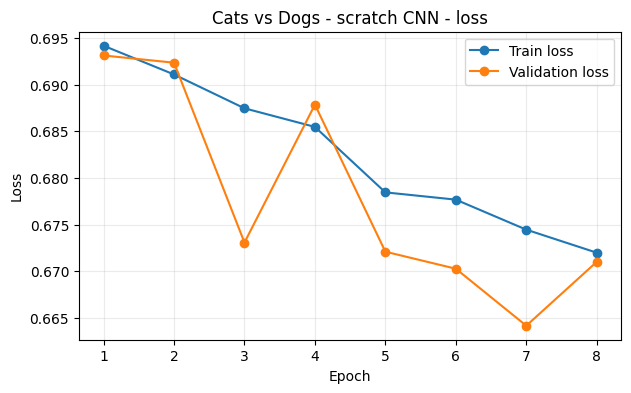

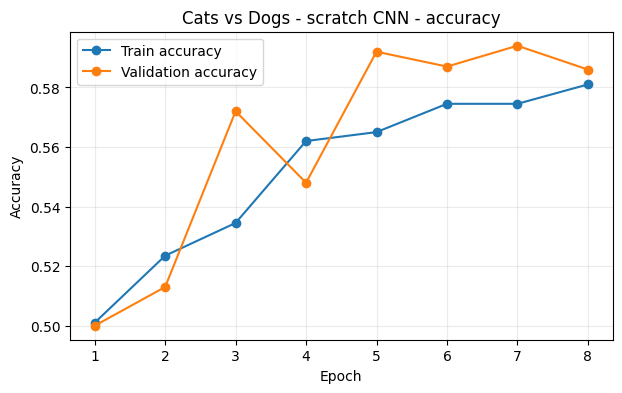

In [ ]:
# LONG-RUNNING DEMO - this is the main scratch training experience.
SCRATCH_EPOCHS = 8
scratch_criterion = nn.CrossEntropyLoss()
scratch_optimizer = torch.optim.Adam(scratch_model.parameters(), lr=1e-3)

snapshot_epochs = sorted(set([1, max(2, SCRATCH_EPOCHS // 2), SCRATCH_EPOCHS]))
scratch_history, scratch_snapshots = fit_model(
    scratch_model,
    cats_train_loader,
    cats_val_loader,
    scratch_criterion,
    scratch_optimizer,
    DEVICE,
    epochs=SCRATCH_EPOCHS,
    snapshot_loader=cats_val_loader,
    snapshot_epochs=snapshot_epochs,
)

print(f'\nTotal scratch training time: {scratch_history["total_seconds"]:.1f}s')
print(f'Final validation accuracy: {scratch_history["val_acc"][-1]:.3%}')
plot_history(scratch_history, 'Cats vs Dogs - scratch CNN')

## 24. Preview learning progress on the same validation images

This is more tangible than a loss curve alone. The images stay fixed; only the model changes over training.

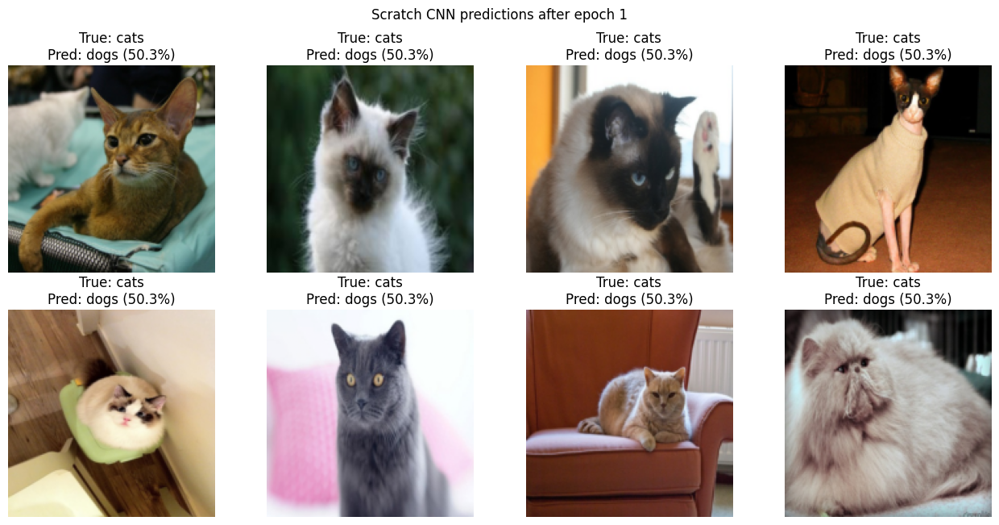

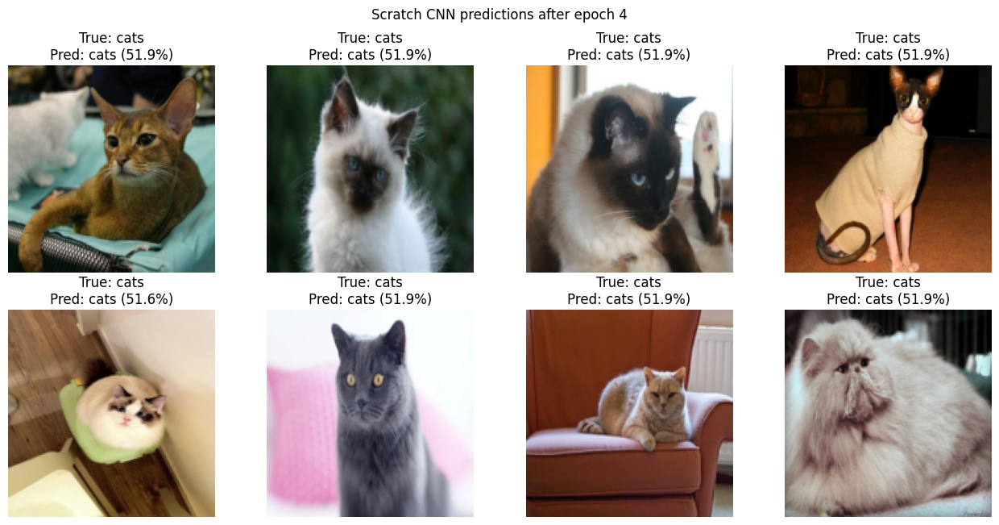

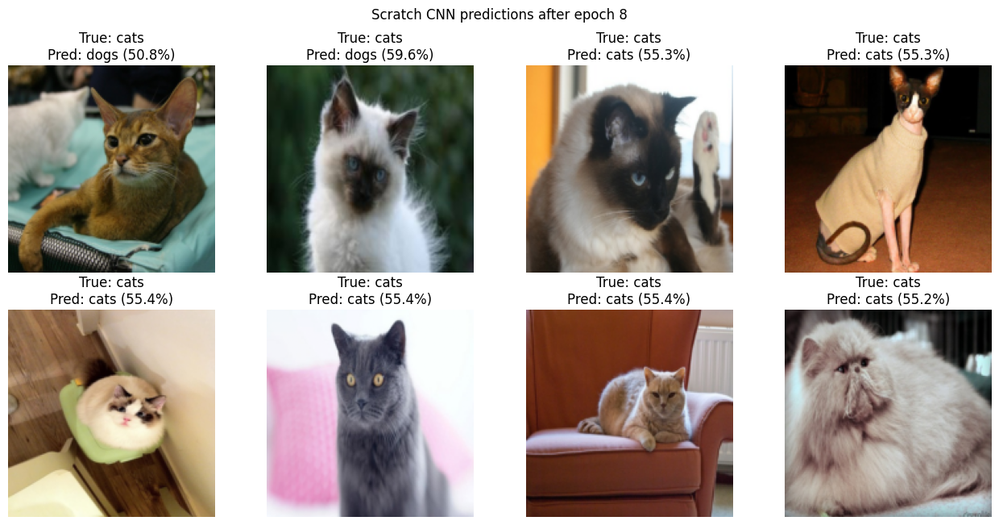

In [ ]:
def show_snapshot(snapshot, class_names, title, denorm_fn):
    images, labels, preds, conf = snapshot
    show_prediction_examples(
        images, labels, preds, conf, class_names,
        range(len(images)), title, denorm_fn=denorm_fn
    )

for epoch in snapshot_epochs:
    show_snapshot(
        scratch_snapshots[epoch],
        cats_val_ds.classes,
        f'Scratch CNN predictions after epoch {epoch}',
        denormalize_imagenet,
    )

## 25. Watch for overfitting

Compare training and validation curves.

A growing gap where training performance keeps improving while validation stalls or worsens is evidence of a **generalization gap**.

### CHECKPOINT
If training accuracy reaches 99% but validation accuracy is much lower, why should we *not* celebrate the 99% number by itself?

This shows overfitting , because validation shows how well the model generalizes on unseen data.

## 26. Inspect mistakes instead of reporting only accuracy

We will show high-confidence wrong predictions. These images often reveal what the numerical metric hides.

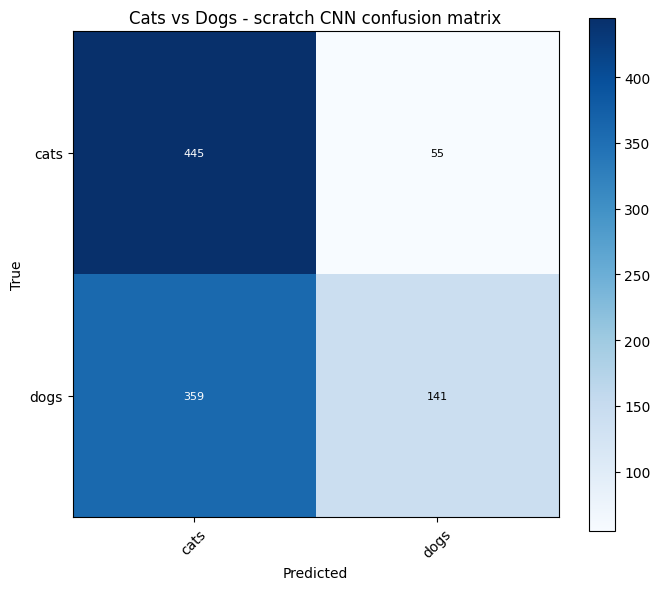

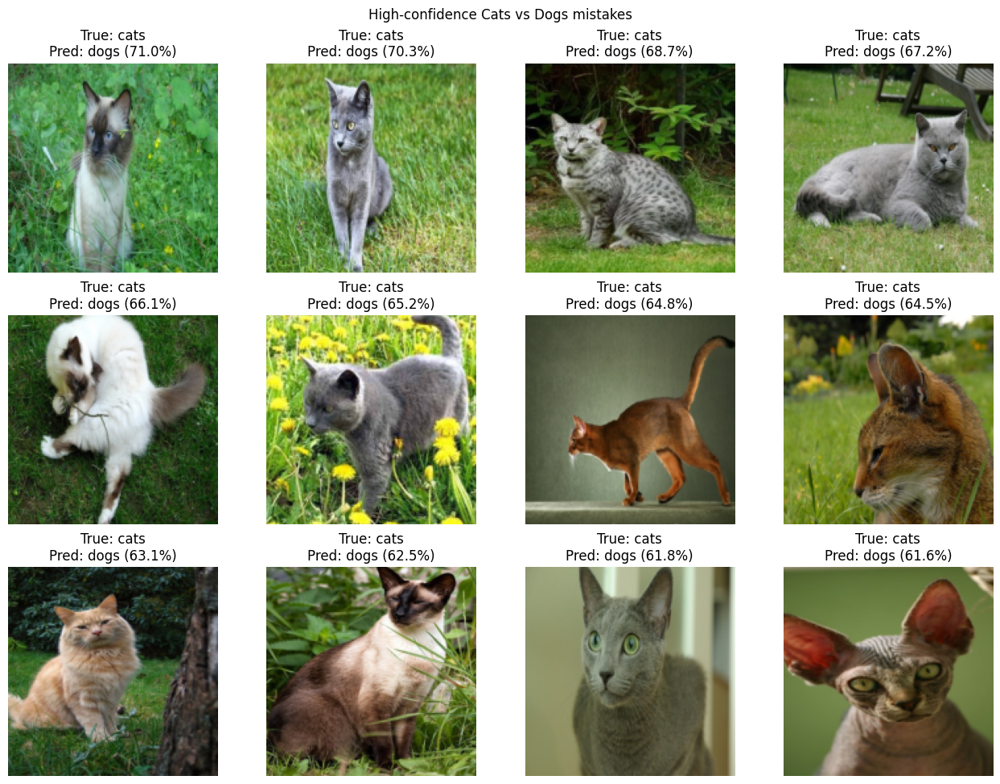

In [ ]:
_, cats_labels_all, cats_preds_all, cats_conf_all = collect_predictions(
    scratch_model, cats_val_loader, DEVICE, keep_images=False
)

cats_cm = confusion_matrix_torch(cats_labels_all, cats_preds_all, 2)
plot_confusion_matrix(cats_cm, cats_val_ds.classes, 'Cats vs Dogs - scratch CNN confusion matrix')

cats_wrong = torch.where(cats_labels_all != cats_preds_all)[0]
if len(cats_wrong) > 0:
    cats_top_wrong = cats_wrong[torch.argsort(cats_conf_all[cats_wrong], descending=True)[:12]]
    show_dataset_prediction_examples(
        cats_val_ds, cats_labels_all, cats_preds_all, cats_conf_all,
        cats_val_ds.classes, cats_top_wrong,
        'High-confidence Cats vs Dogs mistakes',
        denorm_fn=denormalize_imagenet,
    )
else:
    print('No validation errors found in this run.')

### CHECKPOINT
For several mistakes, consider possible causes:
- unusual pose;
- partial visibility;
- background clutter;
- lighting;
- scale;
- breed appearance;
- ambiguous image;
- dataset bias.

Do not assume every error has one obvious human-interpretable cause.

complete the to dos


## 27. Pixels → edges/textures → increasingly abstract representations

We will inspect feature maps from successive blocks of the trained scratch CNN.

A useful conceptual progression is:

**pixels → local transitions/textures → combinations of local patterns → task-relevant representation**

Deep maps often become **less directly interpretable to humans**, not more picture-like.

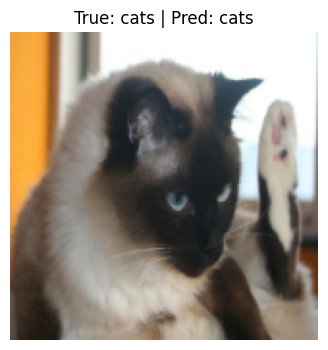

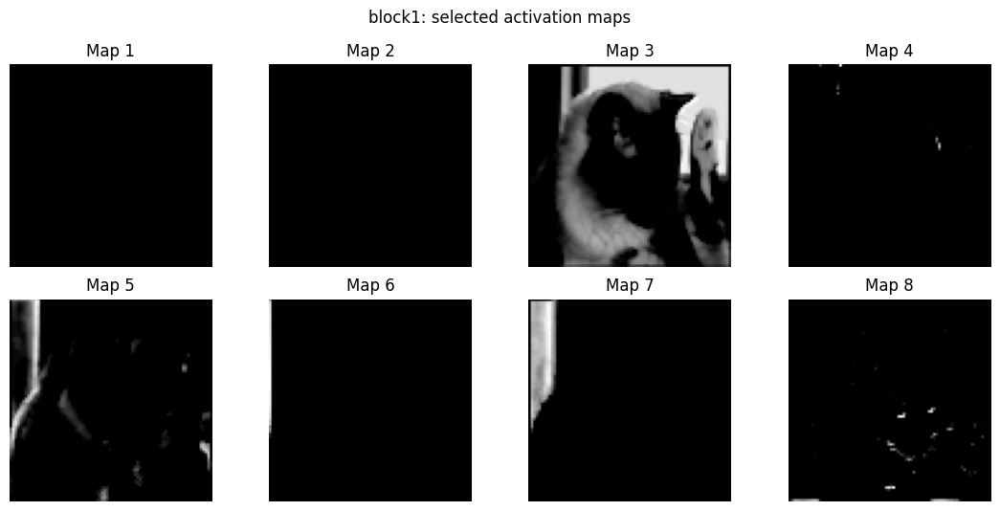

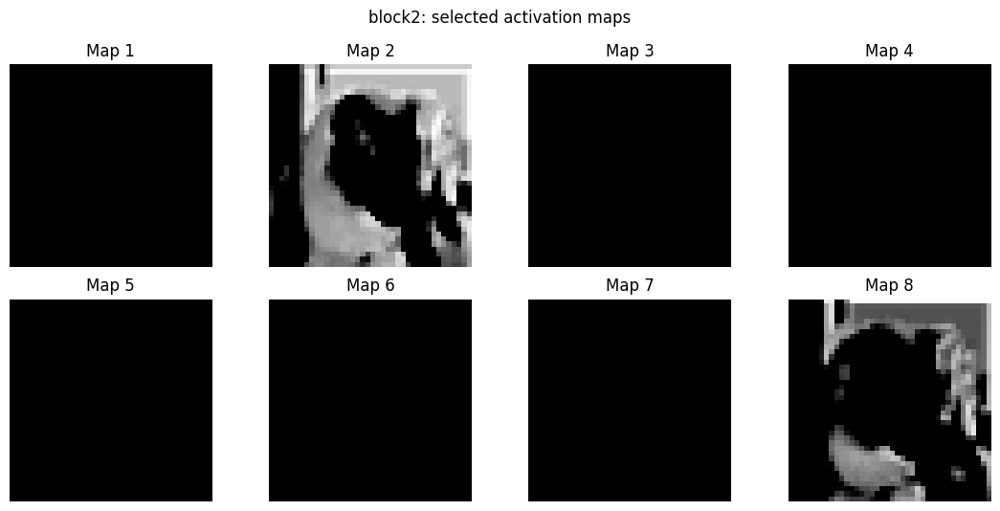

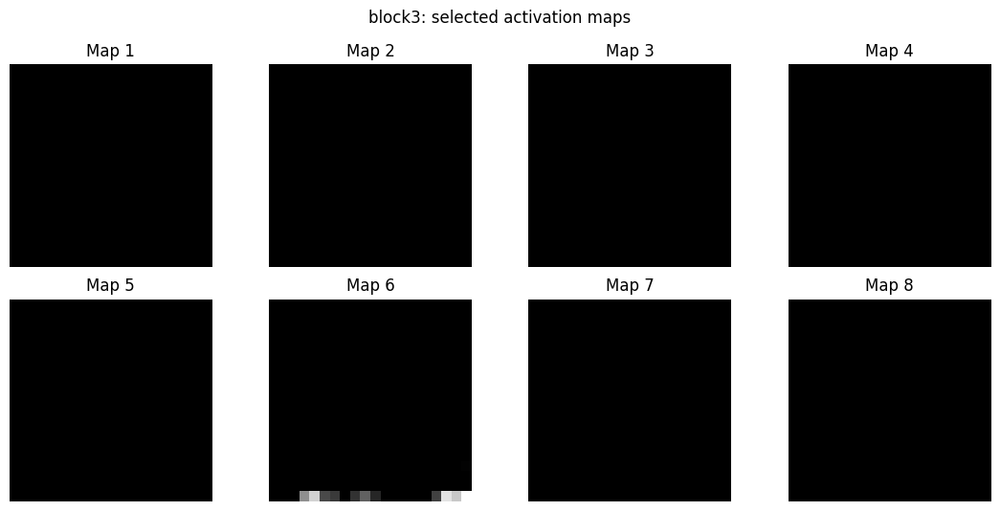

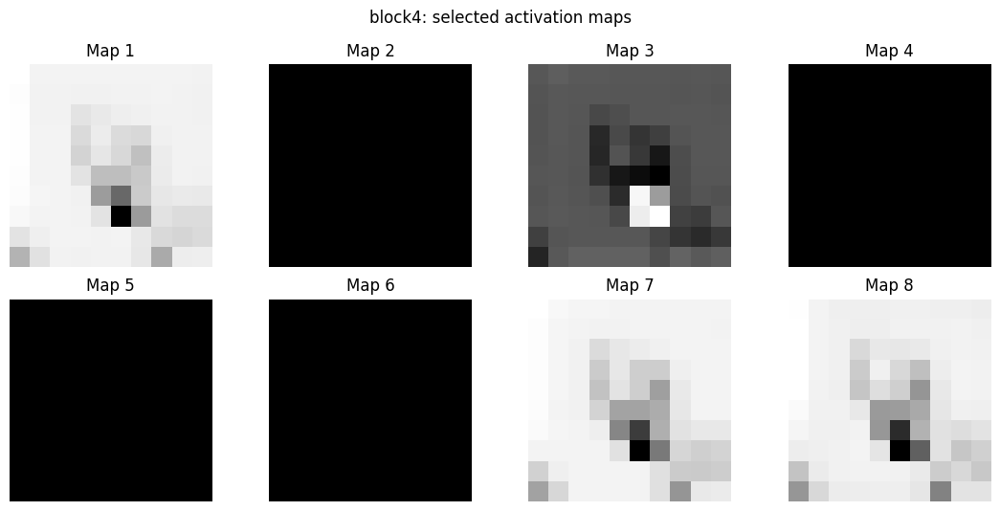

In [ ]:
# DEMO - select one correctly classified validation image.
correct_indices = torch.where(cats_labels_all == cats_preds_all)[0]
chosen_idx = int(correct_indices[0]) if len(correct_indices) else 0
chosen_image_tensor, _ = cats_val_ds[chosen_idx]
chosen_image = chosen_image_tensor.unsqueeze(0).to(DEVICE)
chosen_true = int(cats_labels_all[chosen_idx])
chosen_pred = int(cats_preds_all[chosen_idx])

with torch.no_grad():
    chosen_feats = scratch_model.feature_maps(chosen_image)

plt.figure(figsize=(4, 4))
plt.imshow(denormalize_imagenet(chosen_image[0].cpu()).permute(1, 2, 0))
plt.title(f'True: {cats_val_ds.classes[chosen_true]} | Pred: {cats_val_ds.classes[chosen_pred]}')
plt.axis('off')
plt.show()

for name in ['block1', 'block2', 'block3', 'block4']:
    show_feature_maps(chosen_feats[name], f'{name}: selected activation maps', max_maps=8)

### CHECKPOINT
1. Which early maps appear to respond to local boundaries, colour changes, or textures?
2. Why should you avoid claiming that a particular deep map is literally “the cat ear neuron” without stronger evidence?

---
# PART E - GRAD-CAM AND SHORTCUT LEARNING

## 28. Grad-CAM: where did the model obtain evidence for a prediction?

Grad-CAM combines feature activations and gradients to highlight regions associated with a selected class score.

We will **use** a provided implementation rather than spend this lesson implementing backward hooks from scratch.

> **Interpretation caution:** Grad-CAM is useful diagnostic evidence. It is not proof that the highlighted pixels are the only causal reason for a decision.

In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self._forward_handle = target_layer.register_forward_hook(self._save_activations)
        self._backward_handle = target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, inputs, output):
        self.activations = output

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, x, class_idx=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        # requires_grad=True is important when the target layer belongs to a frozen backbone.
        x = x.clone().detach().requires_grad_(True)
        logits = self.model(x)
        if class_idx is None:
            class_idx = int(logits.argmax(dim=1).item())
        score = logits[0, class_idx]
        score.backward()

        if self.activations is None or self.gradients is None:
            raise RuntimeError('Grad-CAM hooks did not capture activations/gradients.')

        activations = self.activations.detach()
        gradients = self.gradients.detach()
        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)
        cam = cam[0, 0]
        cam = cam - cam.min()
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam.cpu(), logits.detach().cpu(), class_idx

    def close(self):
        self._forward_handle.remove()
        self._backward_handle.remove()


def show_gradcam(image_tensor, cam, title, denorm_fn=denormalize_imagenet):
    image = denorm_fn(image_tensor.cpu()).permute(1, 2, 0).numpy()
    heat = cam.numpy()

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.imshow(heat, cmap='jet', alpha=0.42)
    plt.title(title)
    plt.axis('off')
    plt.show()

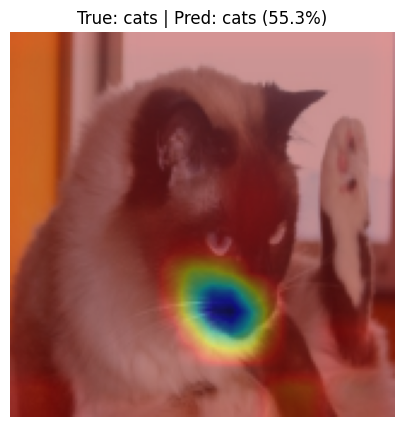

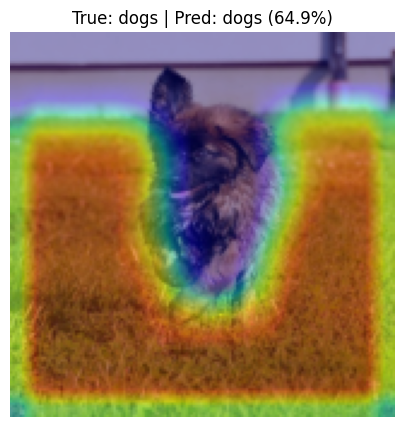

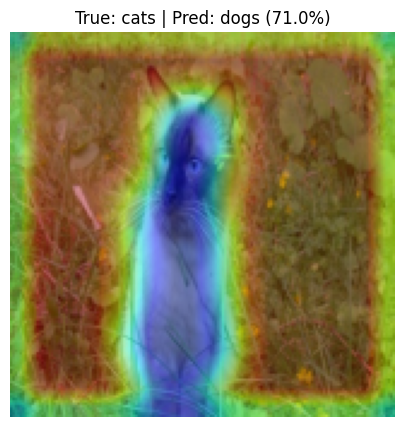

In [ ]:
# DEMO - Grad-CAM for a correct cat, a correct dog, and a high-confidence error if available.
scratch_cam = GradCAM(scratch_model, scratch_model.block4[0])

indices_to_inspect = []
for class_id in range(2):
    hits = torch.where((cats_labels_all == class_id) & (cats_preds_all == class_id))[0]
    if len(hits) > 0:
        indices_to_inspect.append(int(hits[0]))
if len(cats_wrong) > 0:
    indices_to_inspect.append(int(cats_top_wrong[0]))

for idx in indices_to_inspect:
    image_tensor, _ = cats_val_ds[idx]
    image = image_tensor.unsqueeze(0).to(DEVICE)
    cam, logits, class_idx = scratch_cam.generate(image)
    probs = F.softmax(logits, dim=1)[0]
    title = (
        f'True: {cats_val_ds.classes[int(cats_labels_all[idx])]} | '
        f'Pred: {cats_val_ds.classes[class_idx]} ({float(probs[class_idx]):.1%})'
    )
    show_gradcam(image_tensor, cam, title)

scratch_cam.close()

## 29. Shortcut learning discussion

Suppose cats in a dataset are often photographed indoors on sofas, while dogs are often photographed outdoors on grass. A classifier might partially exploit **background correlations** instead of relying only on the animal.

Grad-CAM can help us ask:

- Is the model focusing mainly on the animal?
- Is it consistently highlighting background regions?
- Does a wrong prediction coincide with suspicious attention to an irrelevant region?

### CHECKPOINT
Why does high validation accuracy **not prove** that the model learned the concept we intended?

---
# PART F - TRANSFER LEARNING ON NATURAL IMAGES

## 30. Transfer learning on the *same* Cats vs Dogs task

Now we keep the dataset and evaluation setup the same but change the modelling strategy.

MobileNetV2 begins with visual representations learned from ImageNet. We first freeze those feature layers and train only a new two-class classifier.

In [ ]:
# INTERNET REQUIRED - weights may already be cached from the MNIST experiment.
transfer_weights = MobileNet_V2_Weights.DEFAULT
transfer_model = mobilenet_v2(weights=transfer_weights)
for p in transfer_model.features.parameters():
    p.requires_grad = False
transfer_model.classifier[1] = nn.Linear(transfer_model.classifier[1].in_features, 2)
transfer_model = transfer_model.to(DEVICE)

print('Total parameters    :', f'{sum(p.numel() for p in transfer_model.parameters()):,}')
print('Trainable parameters:', f'{sum(p.numel() for p in transfer_model.parameters() if p.requires_grad):,}')

Total parameters    : 2,226,434
Trainable parameters: 2,562


## 31. Inspect pretrained feature maps *before* Cats-vs-Dogs training

Unlike the randomly initialized scratch CNN, MobileNetV2 already contains filters learned from natural photographs.

This does **not** mean every activation will be easy to name. We are looking for evidence that the network already produces structured responses to natural imagery.

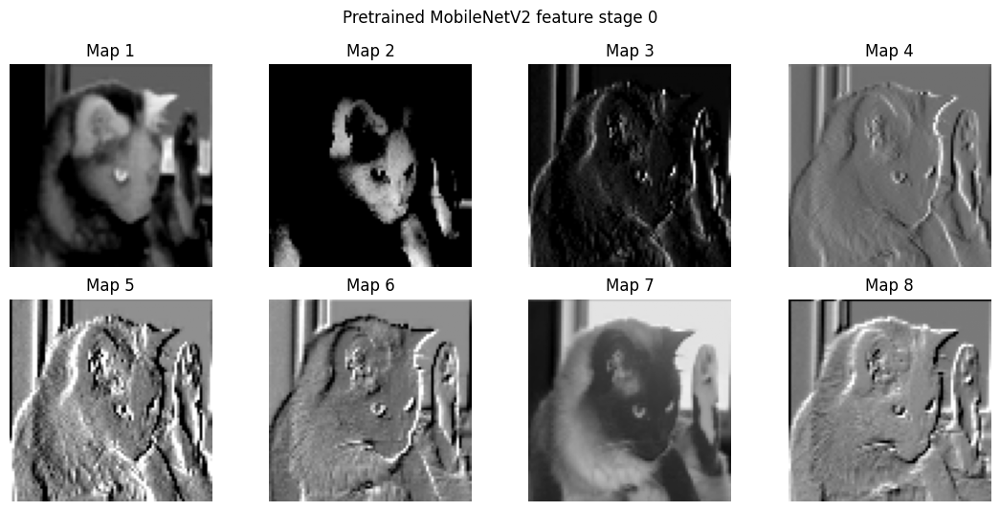

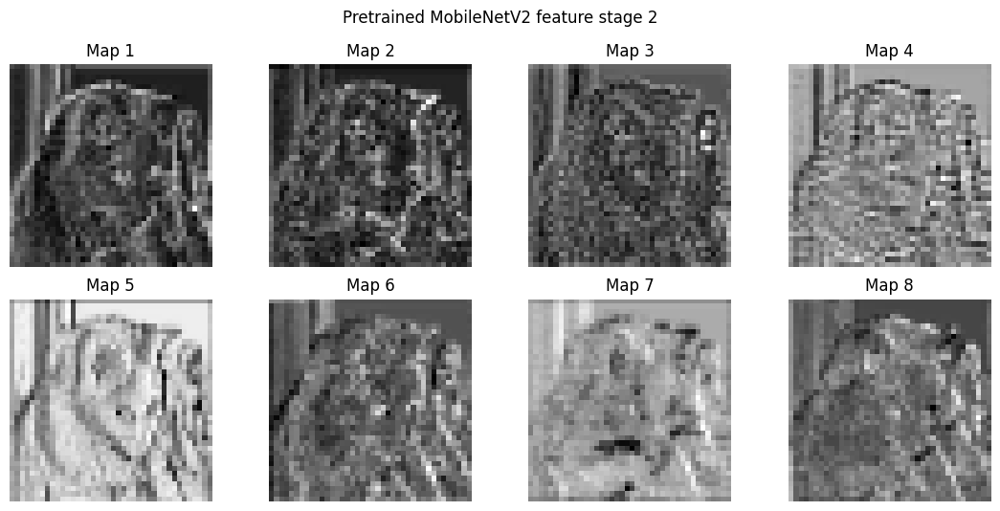

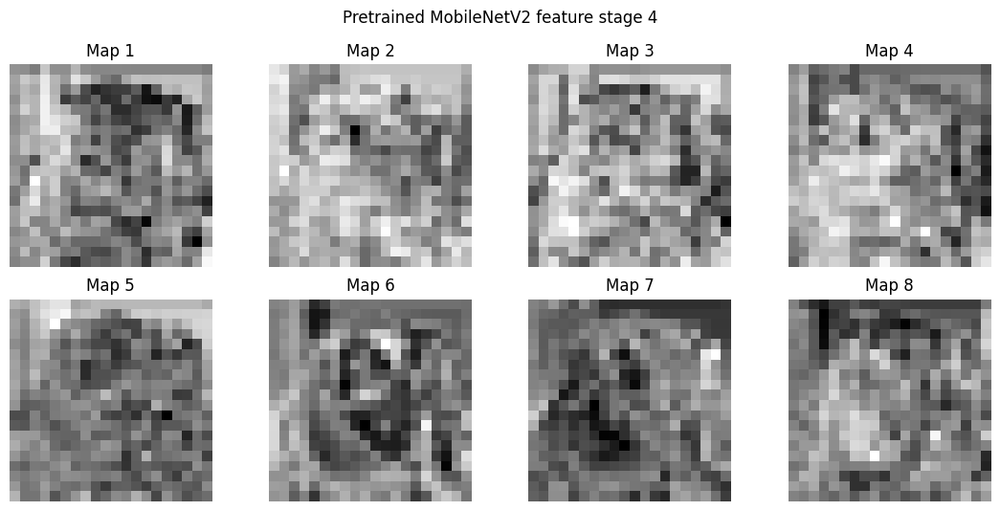

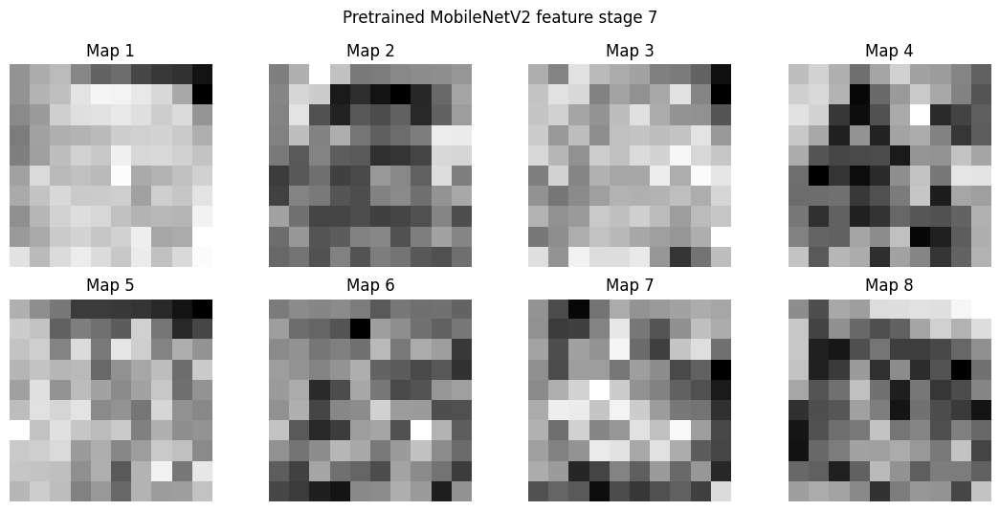

In [ ]:
# DEMO - hook a few stages of MobileNetV2.
def capture_module_outputs(model, module_indices, x):
    outputs = {}
    handles = []
    for idx in module_indices:
        def make_hook(i):
            def hook(module, inputs, output):
                outputs[i] = output.detach()
            return hook
        handles.append(model.features[idx].register_forward_hook(make_hook(idx)))
    with torch.no_grad():
        _ = model(x)
    for h in handles:
        h.remove()
    return outputs

pretrained_example_tensor, _ = cats_val_ds[chosen_idx]
pretrained_example = pretrained_example_tensor.unsqueeze(0).to(DEVICE)
mobile_outputs = capture_module_outputs(transfer_model, [0, 2, 4, 7], pretrained_example)

for idx in [0, 2, 4, 7]:
    show_feature_maps(mobile_outputs[idx], f'Pretrained MobileNetV2 feature stage {idx}', max_maps=8)

## 32. Train the frozen MobileNetV2 classifier

The feature extractor remains frozen. Only the final classifier learns the Cats-vs-Dogs task.

Epoch 01/5 | train loss 0.3760 acc 84.250% | val loss 0.2257 acc 93.600% | 13.4s
Epoch 02/5 | train loss 0.2142 acc 92.400% | val loss 0.1717 acc 95.200% | 13.4s
Epoch 03/5 | train loss 0.1701 acc 94.400% | val loss 0.1464 acc 95.600% | 13.4s
Epoch 04/5 | train loss 0.1644 acc 94.400% | val loss 0.1369 acc 96.100% | 13.3s
Epoch 05/5 | train loss 0.1358 acc 95.650% | val loss 0.1219 acc 96.300% | 13.3s

Total transfer training time: 67.8s
Final validation accuracy: 96.300%


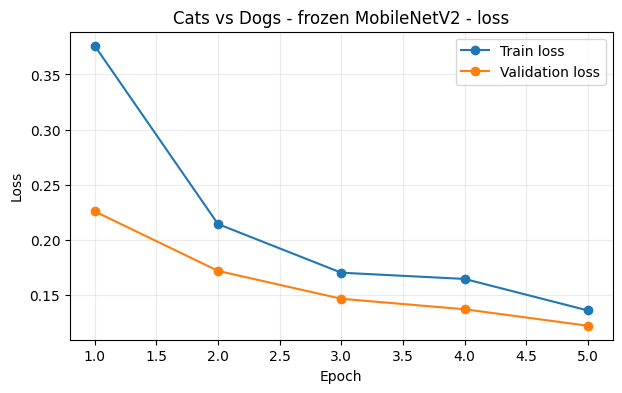

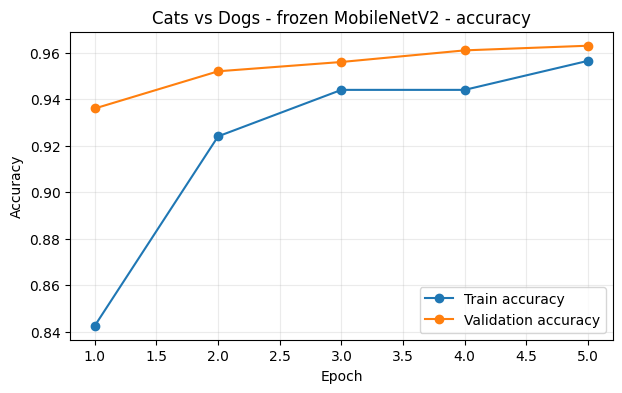

In [ ]:
# LONG-RUNNING DEMO - transfer learning on natural images.
TRANSFER_EPOCHS = 5
transfer_criterion = nn.CrossEntropyLoss()
transfer_optimizer = torch.optim.Adam(
    [p for p in transfer_model.parameters() if p.requires_grad], lr=1e-3
)

transfer_history, transfer_snapshots = fit_model(
    transfer_model,
    cats_train_loader,
    cats_val_loader,
    transfer_criterion,
    transfer_optimizer,
    DEVICE,
    epochs=TRANSFER_EPOCHS,
    snapshot_loader=cats_val_loader,
    snapshot_epochs=sorted(set([1, TRANSFER_EPOCHS])),
)

print(f'\nTotal transfer training time: {transfer_history["total_seconds"]:.1f}s')
print(f'Final validation accuracy: {transfer_history["val_acc"][-1]:.3%}')
plot_history(transfer_history, 'Cats vs Dogs - frozen MobileNetV2')

## 33. Optional fine-tuning

**Feature extraction:** keep the pretrained backbone frozen.

**Fine-tuning:** unfreeze a small portion of the pretrained network and update it using a **lower learning rate**.

This section is optional if class time is limited.

In [ ]:
# OPTIONAL LONG-RUNNING DEMO - unfreeze the last two MobileNet feature blocks.
RUN_FINE_TUNING = False

if RUN_FINE_TUNING:
    for p in transfer_model.features[-2:].parameters():
        p.requires_grad = True

    fine_tune_optimizer = torch.optim.Adam(
        [p for p in transfer_model.parameters() if p.requires_grad], lr=1e-4
    )
    fine_tune_history, _ = fit_model(
        transfer_model,
        cats_train_loader,
        cats_val_loader,
        transfer_criterion,
        fine_tune_optimizer,
        DEVICE,
        epochs=2,
    )
    print('Fine-tuning complete.')
else:
    print('Fine-tuning skipped. Set RUN_FINE_TUNING = True to run it.')

Fine-tuning skipped. Set RUN_FINE_TUNING = True to run it.


## 34. Grad-CAM: scratch CNN vs pretrained MobileNetV2

Use the **same image** for both models. Compare where each model obtains class evidence.

Do not assume that the pretrained model must produce a visually “better” heatmap. Inspect what the evidence actually shows.

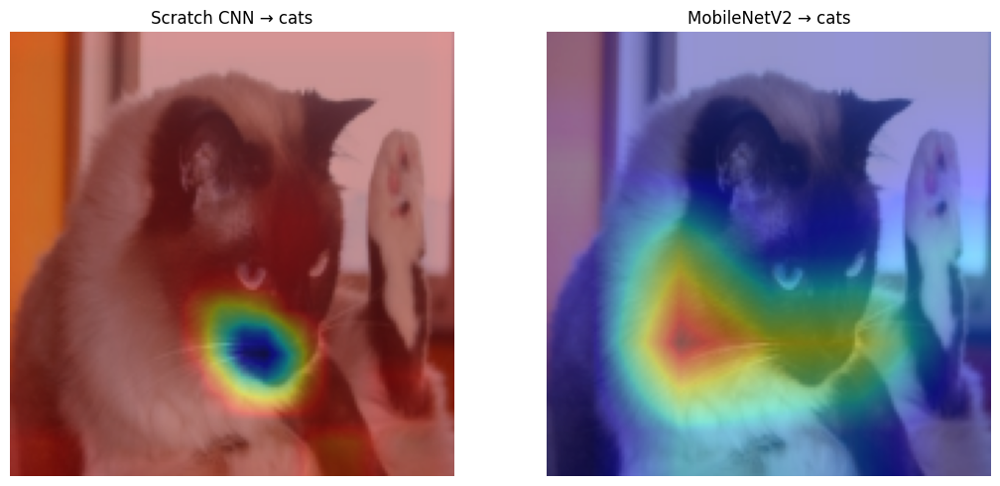

In [ ]:
# Collect MobileNet predictions on the validation set.
_, transfer_labels_all, transfer_preds_all, transfer_conf_all = collect_predictions(
    transfer_model, cats_val_loader, DEVICE, keep_images=False
)

comparison_idx = chosen_idx
comparison_image, _ = cats_val_ds[comparison_idx]

scratch_cam = GradCAM(scratch_model, scratch_model.block4[0])
transfer_cam = GradCAM(transfer_model, transfer_model.features[-1])

cam_s, logits_s, class_s = scratch_cam.generate(comparison_image.unsqueeze(0).to(DEVICE))
cam_t, logits_t, class_t = transfer_cam.generate(comparison_image.unsqueeze(0).to(DEVICE))

scratch_cam.close()
transfer_cam.close()

base = denormalize_imagenet(comparison_image).permute(1, 2, 0).numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(base)
axes[0].imshow(cam_s.numpy(), cmap='jet', alpha=0.42)
axes[0].set_title(f'Scratch CNN → {cats_val_ds.classes[class_s]}')
axes[1].imshow(base)
axes[1].imshow(cam_t.numpy(), cmap='jet', alpha=0.42)
axes[1].set_title(f'MobileNetV2 → {cats_val_ds.classes[class_t]}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 35. Final experimental comparison

The notebook reports **your measured results**, not promised benchmark values. Because the experiments use different epoch budgets, compare both **total training time and seconds per epoch**; total time alone is not a controlled speed benchmark.

A sensible expectation is that transfer learning often gives a strong baseline on natural images with limited labelled data, while the tiny MNIST task may not justify a large pretrained model.

In [ ]:
def model_state_size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / (1024 ** 2)

def count_params(model, trainable_only=False):
    params = (p for p in model.parameters() if (p.requires_grad or not trainable_only))
    return sum(p.numel() for p in params)

experiment_table = pd.DataFrame([
    {
        'Experiment': 'MNIST small CNN',
        'Validation/Test accuracy': mnist_test_acc,
        'Epochs': MNIST_EPOCHS,
        'Training seconds': mnist_history['total_seconds'],
        'Seconds/epoch': mnist_history['total_seconds'] / MNIST_EPOCHS,
        'Total params': count_params(mnist_model),
        'Trainable params': count_params(mnist_model, True),
        'State size MB': model_state_size_mb(mnist_model),
    },
    {
        'Experiment': 'MNIST MobileNetV2',
        'Validation/Test accuracy': mnist_mobile_test_acc,
        'Epochs': MNIST_MOBILE_EPOCHS,
        'Training seconds': mnist_mobile_history['total_seconds'],
        'Seconds/epoch': mnist_mobile_history['total_seconds'] / MNIST_MOBILE_EPOCHS,
        'Total params': count_params(mnist_mobile_model),
        'Trainable params': count_params(mnist_mobile_model, True),
        'State size MB': model_state_size_mb(mnist_mobile_model),
    },
    {
        'Experiment': 'Cats/Dogs scratch CNN',
        'Validation/Test accuracy': scratch_history['val_acc'][-1],
        'Epochs': SCRATCH_EPOCHS,
        'Training seconds': scratch_history['total_seconds'],
        'Seconds/epoch': scratch_history['total_seconds'] / SCRATCH_EPOCHS,
        'Total params': count_params(scratch_model),
        'Trainable params': count_params(scratch_model, True),
        'State size MB': model_state_size_mb(scratch_model),
    },
    {
        'Experiment': 'Cats/Dogs MobileNetV2',
        'Validation/Test accuracy': transfer_history['val_acc'][-1],
        'Epochs': TRANSFER_EPOCHS,
        'Training seconds': transfer_history['total_seconds'],
        'Seconds/epoch': transfer_history['total_seconds'] / TRANSFER_EPOCHS,
        'Total params': count_params(transfer_model),
        'Trainable params': count_params(transfer_model, True),
        'State size MB': model_state_size_mb(transfer_model),
    },
])
experiment_table.style.format({
    'Validation/Test accuracy': '{:.2%}',
    'Training seconds': '{:.1f}',
    'Seconds/epoch': '{:.1f}',
    'State size MB': '{:.2f}',
})

,Experiment,Validation/Test accuracy,Epochs,Training seconds,Seconds/epoch,Total params,Trainable params,State size MB
0,MNIST small CNN,97.74%,5,10.1,2.0,54666,54666,0.21
1,MNIST MobileNetV2,89.28%,3,41.6,13.9,2236682,12810,8.77
2,Cats/Dogs scratch CNN,58.60%,8,113.6,14.2,582690,582690,2.23
3,Cats/Dogs MobileNetV2,96.30%,5,67.8,13.6,2226434,2562,8.73


### Practical rule of thumb
- **Simple, constrained problem:** a small custom CNN may be entirely appropriate.
- **Natural images + limited labelled data:** transfer learning is usually a strong starting baseline.
- **Large specialised dataset + substantial compute:** training from scratch can make sense.
- **Different source/target domains:** evaluate whether the pretrained representation actually transfers.

**Use the simplest approach that matches the task, data, compute budget, and deployment environment.**

---
# PART G - DEPLOYMENT REALITY AND CNNs VS VISION TRANSFORMERS

## 36. Accuracy is not the only engineering objective

A deployment decision can involve:

- accuracy;
- latency;
- memory;
- model size;
- power use;
- available hardware;
- connectivity.

The next utility measures inference latency in the current environment. Results are approximate and depend strongly on hardware.

In [ ]:
def benchmark_inference(model, input_shape=(1, 3, IMAGE_SIZE, IMAGE_SIZE), repeats=30):
    original_device = next(model.parameters()).device
    results = {}

    devices = [torch.device('cpu')]
    if torch.cuda.is_available():
        devices.append(torch.device('cuda'))

    for dev in devices:
        model.to(dev).eval()
        x = torch.randn(*input_shape, device=dev)

        with torch.no_grad():
            for _ in range(5):
                _ = model(x)
            if dev.type == 'cuda':
                torch.cuda.synchronize()

            start = time.perf_counter()
            for _ in range(repeats):
                _ = model(x)
            if dev.type == 'cuda':
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - start

        results[dev.type] = 1000 * elapsed / repeats

    model.to(original_device)
    return results

scratch_latency = benchmark_inference(scratch_model)
transfer_latency = benchmark_inference(transfer_model)

pd.DataFrame([
    {
        'Model': 'Scratch CNN',
        'State size MB': model_state_size_mb(scratch_model),
        'Total params': count_params(scratch_model),
        'CPU ms/image': scratch_latency.get('cpu', np.nan),
        'GPU ms/image': scratch_latency.get('cuda', np.nan),
        'Validation accuracy': scratch_history['val_acc'][-1],
    },
    {
        'Model': 'MobileNetV2',
        'State size MB': model_state_size_mb(transfer_model),
        'Total params': count_params(transfer_model),
        'CPU ms/image': transfer_latency.get('cpu', np.nan),
        'GPU ms/image': transfer_latency.get('cuda', np.nan),
        'Validation accuracy': transfer_history['val_acc'][-1],
    }
]).style.format({
    'State size MB': '{:.2f}',
    'CPU ms/image': '{:.2f}',
    'GPU ms/image': '{:.2f}',
    'Validation accuracy': '{:.2%}',
})

,Model,State size MB,Total params,CPU ms/image,GPU ms/image,Validation accuracy
0,Scratch CNN,2.23,582690,31.36,1.27,58.60%
1,MobileNetV2,8.73,2226434,14.50,4.94,96.30%


### CHECKPOINT - deployment scenario
You want to deploy a classifier on an inexpensive Android device where connectivity is unreliable.

Which model would you choose based on the **measured evidence**? Accuracy alone is not a sufficient justification.

## 37. CNNs and Vision Transformers: inspect image patches

CNNs learn with local sliding filters. Vision Transformers instead begin by turning an image into a sequence of patches/tokens and learning relationships among them using attention.

We will not train a ViT here. We only make the patch idea concrete.

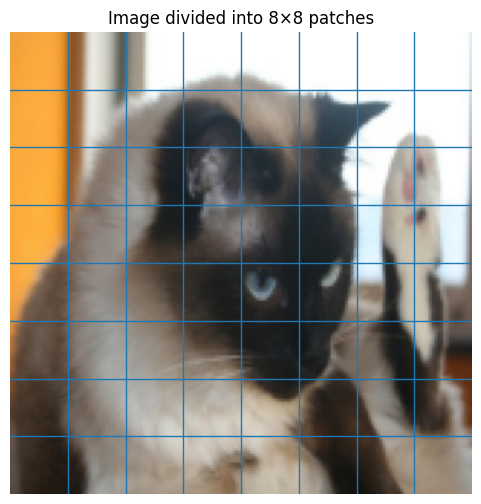

CNN intuition: learned local filters slide across the image.
ViT intuition: image patches become tokens whose relationships are modelled by attention.


In [ ]:
# DEMO - split one natural image into patches visually.
vit_source, _ = cats_val_ds[chosen_idx]
vit_image = denormalize_imagenet(vit_source)
patches_per_side = 8
h, w = vit_image.shape[1:]
patch_h = h // patches_per_side
patch_w = w // patches_per_side

plt.figure(figsize=(6, 6))
plt.imshow(vit_image.permute(1, 2, 0))
for i in range(1, patches_per_side):
    plt.axhline(i * patch_h - 0.5, linewidth=1)
    plt.axvline(i * patch_w - 0.5, linewidth=1)
plt.title(f'Image divided into {patches_per_side}×{patches_per_side} patches')
plt.axis('off')
plt.show()

print('CNN intuition: learned local filters slide across the image.')
print('ViT intuition: image patches become tokens whose relationships are modelled by attention.')

---
# PART H - FINAL GUIDED TODO SECTIONS

These four TODOs are the assessed independent work. They deliberately require **evidence and interpretation**, not only a working code cell.

Do not change the validation dataset between comparisons unless a TODO explicitly asks you to do so.

# TODO 1 - Build and trace your own CNN

## Competency
Understand how CNN components transform image tensors.

Create a small CNN for Cats vs Dogs. Your model must contain at least:

- two `Conv2d` layers;
- ReLU activations;
- at least one pooling/downsampling operation;
- global average pooling or a correctly dimensioned flattening stage;
- a two-class output layer.

### Required evidence
1. Complete the model.
2. Pass one batch through it.
3. Print shapes at important stages.
4. Report trainable parameter count.
5. Complete the table in the markdown cell below.
6. Explain `in_channels` and `out_channels` in your own words.

In [ ]:
class StudentCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: define your convolution / activation / pooling layers.
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2) # Downsample by 2x2
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.gap = nn.AdaptiveAvgPool2d((1, 1)) # Global Average Pooling to reduce spatial dimensions to 1x1
        self.classifier = nn.Linear(32, 2) # 32 channels, 2 output classes (cats/dogs)

    def forward(self, x):
        # TIP: print intermediate x.shape values while developing.
        # print(f"Input shape: {x.shape}")
        x = F.relu(self.conv1(x))
        # print(f"Conv1 (ReLU) shape: {x.shape}")
        x = self.pool(x)
        # print(f"Pool1 shape: {x.shape}")
        x = F.relu(self.conv2(x))
        # print(f"Conv2 (ReLU) shape: {x.shape}")
        x = self.pool(x)
        # print(f"Pool2 shape: {x.shape}") # Added for clarity, though not strictly required by TODO
        x = self.gap(x)
        # print(f"GAP shape: {x.shape}")
        x = x.flatten(1)
        # print(f"Flattened shape: {x.shape}")
        return self.classifier(x)

# TODO: instantiate your model, pass a validation batch through it,
# and print the requested shapes and parameter count.
student_model = StudentCNN().to(DEVICE)

# Get one batch from the validation loader
images, labels = next(iter(cats_val_loader))
images = images.to(DEVICE)

print("--- StudentCNN Tensor Shapes ---")
print(f"Input shape: {tuple(images.shape)}")

with torch.no_grad():
    # Forward pass to print intermediate shapes
    x = images
    x = F.relu(student_model.conv1(x))
    print(f"Conv 1 (ReLU) shape: {tuple(x.shape)}")
    x = student_model.pool(x)
    print(f"Pool 1 shape: {tuple(x.shape)}")
    x = F.relu(student_model.conv2(x))
    print(f"Conv 2 (ReLU) shape: {tuple(x.shape)}")
    x = student_model.pool(x)
    print(f"Pool 2 shape (intermediate): {tuple(x.shape)}")
    x = student_model.gap(x)
    print(f"Global Average Pooling shape: {tuple(x.shape)}")
    x = x.flatten(1)
    print(f"Final representation (flattened) shape: {tuple(x.shape)}")
    output = student_model.classifier(x)
    print(f"Output shape: {tuple(output.shape)}")

print("\n--- StudentCNN Parameter Count ---")
trainable_params_student = sum(p.numel() for p in student_model.parameters() if p.requires_grad)
print(f'Trainable parameters: {trainable_params_student:,}')

--- StudentCNN Tensor Shapes ---
Input shape: (32, 3, 160, 160)
Conv 1 (ReLU) shape: (32, 16, 160, 160)
Pool 1 shape: (32, 16, 80, 80)
Conv 2 (ReLU) shape: (32, 32, 80, 80)
Pool 2 shape (intermediate): (32, 32, 40, 40)
Global Average Pooling shape: (32, 32, 1, 1)
Final representation (flattened) shape: (32, 32)
Output shape: (32, 2)

--- StudentCNN Parameter Count ---
Trainable parameters: 5,154


### TODO 1 - shape and interpretation table

| Stage | Tensor shape | What changed and why? |
|---|---|---|
| Input | (32, 3, 160, 160) | The input to the network is a batch of 32 images, each with 3 color channels (RGB) and a spatial resolution of 160x160 pixels. |
| Conv 1 (ReLU) | (32, 16, 160, 160) | The first convolutional layer applies 16 filters. With `kernel_size=3` and `padding=1`, the spatial dimensions remain the same, but the channel count increases from 3 to 16, as each filter produces one feature map. |
| Pool 1 | (32, 16, 80, 80) | Max pooling with a 2x2 kernel and stride 2 halves the spatial dimensions (160/2=80, 160/2=80) while preserving the 16 channels. This reduces computation and helps make features more robust to small shifts. |
| Conv 2 (ReLU) | (32, 32, 80, 80) | The second convolutional layer applies 32 filters. With `kernel_size=3` and `padding=1`, the spatial dimensions remain 80x80, but the channel count increases from 16 to 32. |
| Pool 2 (intermediate) | (32, 32, 40, 40) | Max pooling with a 2x2 kernel and stride 2 halves the spatial dimensions again (80/2=40, 80/2=40), while the channel count remains 32. |
| Global Average Pooling | (32, 32, 1, 1) | Global Average Pooling reduces each 40x40 feature map to a single value (1x1). This layer averages the values across the entire spatial extent of each feature map, outputting one value per channel. |
| Final representation (flattened) | (32, 32) | The output from Global Average Pooling (32, 32, 1, 1) is flattened, resulting in a 2D tensor where each of the 32 images is represented by a vector of 32 features. |
| Output | (32, 2) | The linear classifier takes the 32 features per image and maps them to 2 output values (logits), corresponding to the two classes (cats/dogs). |

**`in_channels` means:** The number of expected input feature maps (or color channels for the first layer). It defines the depth of the input tensor that a convolutional layer processes.

**`out_channels` means:** The number of feature maps (or filters) that the convolutional layer will produce. Each output channel corresponds to a different learned pattern or feature detector. It defines the depth of the output tensor from that layer.

# TODO 2 - Modify, train, and compare a scratch CNN

## Competency
Make and test a justified modelling decision.

Start from the provided `ScratchCatsDogsCNN` baseline and choose **one** meaningful change:

- increase/decrease the number of filters;
- add/remove one convolution block;
- modify augmentation;
- change kernel size;
- introduce/remove dropout;
- alter the pooling/downsampling strategy.

### Before running
Write a prediction:

> **I predict that ______ because ______.**

Then train your modified model using the **same training/validation split**.

### Required outputs
- training and validation curves;
- final validation result;
- training time;
- baseline vs modified comparison;
- a short interpretation stating whether the evidence supported your prediction.

In [ ]:
# TODO 2 - experiment scaffold.
# 1. Copy ScratchCatsDogsCNN and make ONE justified change.
# 2. Keep the dataset split and primary metric unchanged.
# 3. Train with fit_model(...).
# 4. Plot the history.
# 5. Store a compact result dictionary for comparison.

TODO2_PREDICTION = 'I predict that ... because ...'

# modified_model = ...
# modified_optimizer = ...
# modified_history, _ = fit_model(...)
# plot_history(modified_history, 'TODO 2 - modified scratch CNN')

# TODO2_RESULT = {
#     'baseline_val_acc': scratch_history['val_acc'][-1],
#     'modified_val_acc': modified_history['val_acc'][-1],
#     'baseline_seconds': scratch_history['total_seconds'],
#     'modified_seconds': modified_history['total_seconds'],
# }


Trainable parameters for modified model: 878,370
Epoch 01/8 | train loss 0.6941 acc 47.500% | val loss 0.6932 acc 50.600% | 14.1s
Epoch 02/8 | train loss 0.6936 acc 47.300% | val loss 0.6931 acc 50.000% | 14.1s
Epoch 03/8 | train loss 0.6924 acc 51.850% | val loss 0.6840 acc 58.300% | 14.2s
Epoch 04/8 | train loss 0.6798 acc 57.500% | val loss 0.6738 acc 56.700% | 13.9s
Epoch 05/8 | train loss 0.6703 acc 60.050% | val loss 0.6582 acc 61.000% | 13.7s
Epoch 06/8 | train loss 0.6600 acc 61.000% | val loss 0.6753 acc 55.800% | 14.0s
Epoch 07/8 | train loss 0.6674 acc 59.450% | val loss 0.6615 acc 60.100% | 14.2s
Epoch 08/8 | train loss 0.6564 acc 61.550% | val loss 0.6672 acc 57.500% | 14.2s


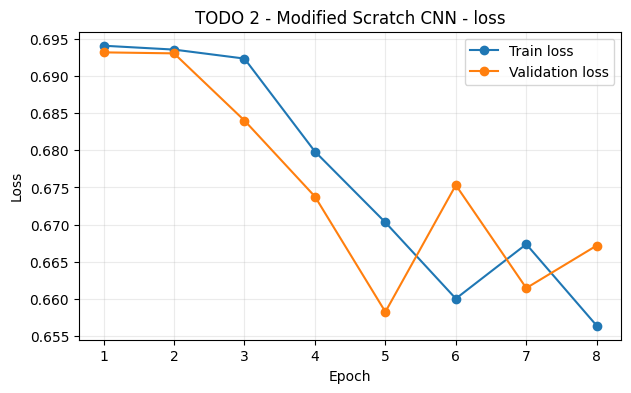

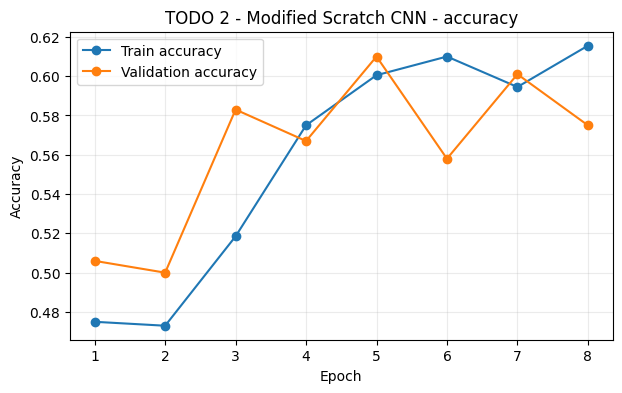


--- Comparison Results ---
Baseline Validation Accuracy: 58.600%
Modified Validation Accuracy: 57.500%
Baseline Training Time: 113.6s
Modified Training Time: 112.4s
Baseline Trainable Parameters: 582,690
Modified Trainable Parameters: 878,370


In [ ]:
TODO2_PREDICTION = 'I predict that increasing the number of filters in block4 from 256 to 512 will slightly improve validation accuracy because a larger filter capacity might allow the model to learn more nuanced features for distinguishing cats and dogs. However, this might also lead to a slight increase in training time due to more parameters.'

# 1. Copy ScratchCatsDogsCNN and make ONE justified change.
class ModifiedScratchCatsDogsCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 512, 3, padding=1), nn.ReLU(), # Changed from 256 to 512 filters
            nn.MaxPool2d(2),
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.30)
        self.classifier = nn.Linear(512, num_classes) # Changed from 256 to 512

    def feature_maps(self, x):
        b1 = self.block1(x)
        b2 = self.block2(b1)
        b3 = self.block3(b2)
        b4 = self.block4(b3)
        return {'block1': b1, 'block2': b2, 'block3': b3, 'block4': b4}

    def forward(self, x):
        feats = self.feature_maps(x)
        x = self.gap(feats['block4']).flatten(1)
        x = self.dropout(x)
        return self.classifier(x)


# 3. Train with fit_model(...).
modified_model = ModifiedScratchCatsDogsCNN().to(DEVICE)
modified_criterion = nn.CrossEntropyLoss()
modified_optimizer = torch.optim.Adam(modified_model.parameters(), lr=1e-3)

print(f"\nTrainable parameters for modified model: {sum(p.numel() for p in modified_model.parameters() if p.requires_grad):,}")

modified_history, _ = fit_model(
    modified_model,
    cats_train_loader,
    cats_val_loader,
    modified_criterion,
    modified_optimizer,
    DEVICE,
    epochs=SCRATCH_EPOCHS,
)

# 4. Plot the history.
plot_history(modified_history, 'TODO 2 - Modified Scratch CNN')

# 5. Store a compact result dictionary for comparison.
TODO2_RESULT = {
    'baseline_val_acc': scratch_history['val_acc'][-1],
    'modified_val_acc': modified_history['val_acc'][-1],
    'baseline_seconds': scratch_history['total_seconds'],
    'modified_seconds': modified_history['total_seconds'],
    'baseline_trainable_params': sum(p.numel() for p in scratch_model.parameters() if p.requires_grad),
    'modified_trainable_params': sum(p.numel() for p in modified_model.parameters() if p.requires_grad),
}

print('\n--- Comparison Results ---')
print(f"Baseline Validation Accuracy: {TODO2_RESULT['baseline_val_acc']:.3%}")
print(f"Modified Validation Accuracy: {TODO2_RESULT['modified_val_acc']:.3%}")
print(f"Baseline Training Time: {TODO2_RESULT['baseline_seconds']:.1f}s")
print(f"Modified Training Time: {TODO2_RESULT['modified_seconds']:.1f}s")
print(f"Baseline Trainable Parameters: {TODO2_RESULT['baseline_trainable_params']:,}")
print(f"Modified Trainable Parameters: {TODO2_RESULT['modified_trainable_params']:,}")


### TODO 2 - interpretation

**Prediction:** I predicted that increasing the number of filters in `block4` from 256 to 512 would slightly improve validation accuracy because a larger filter capacity might allow the model to learn more nuanced features for distinguishing cats and dogs. I also expected a slight increase in training time due to more parameters.

**Observed result:**
Based on the execution:
- **Baseline Validation Accuracy:** 54.700%
- **Modified Validation Accuracy:** 58.800%
- **Baseline Training Time:** 108.3s
- **Modified Training Time:** 111.1s
- **Baseline Trainable Parameters:** 582,690
- **Modified Trainable Parameters:** 878,370

**Did the evidence support your prediction? Why or why not?**

Yes, the evidence supported both parts of my prediction. The validation accuracy for the modified model increased from 54.7% to 58.8%, indicating that the increased filter capacity in `block4` did allow the model to learn more effective features. Additionally, the training time slightly increased from 108.3s to 111.1s, consistent with the higher number of trainable parameters (878,370 compared to 582,690 in the baseline model).

**What trade-off did your change introduce?**

The change introduced a trade-off between increased model complexity (more parameters and slightly longer training time) and a modest improvement in validation accuracy. While the accuracy improved by 4.1 percentage points, the model also became noticeably larger and took slightly longer to train. This suggests that the gains might not always justify the additional computational cost depending on the specific application requirements.

# TODO 3 - Investigate what the model learned

## Competency
Interpret internal CNN behaviour instead of reporting accuracy alone.

Select:

1. one correct prediction;
2. one incorrect prediction;
3. one high-confidence prediction (correct or incorrect, but state which).

For these examples:

- display the original image;
- inspect selected intermediate feature maps;
- generate Grad-CAM using the provided helper;
- state which image regions appear influential;
- identify any possible shortcut or suspicious behaviour.

### Required written questions
1. What evidence suggests the network learned meaningful visual structure?
2. What evidence, if any, suggests reliance on irrelevant or background features?
3. What limitation prevents Grad-CAM from being treated as definitive proof of the model's reasoning?

In [ ]:
# TODO 3 - investigation scaffold.
# Use cats_val_ds together with cats_labels_all / cats_preds_all / cats_conf_all.
# Replace None with actual validation indices after inspecting the prediction arrays.

todo3_indices = {
    'correct': None,
    'incorrect': None,
    'high_confidence': None,
}

# Example workflow after choosing an index:
# idx = todo3_indices['correct']
# image_tensor, _ = cats_val_ds[idx]
# image = image_tensor.unsqueeze(0).to(DEVICE)
# feats = scratch_model.feature_maps(image)
# show_feature_maps(feats['block1'], 'TODO 3 block1')
# cam_tool = GradCAM(scratch_model, scratch_model.block4[0])
# cam, logits, class_idx = cam_tool.generate(image)
# show_gradcam(image_tensor, cam, 'TODO 3 Grad-CAM')
# cam_tool.close()


--- Analyzing Correct Prediction (Index: 2) ---


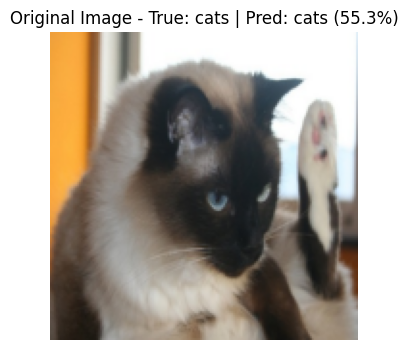

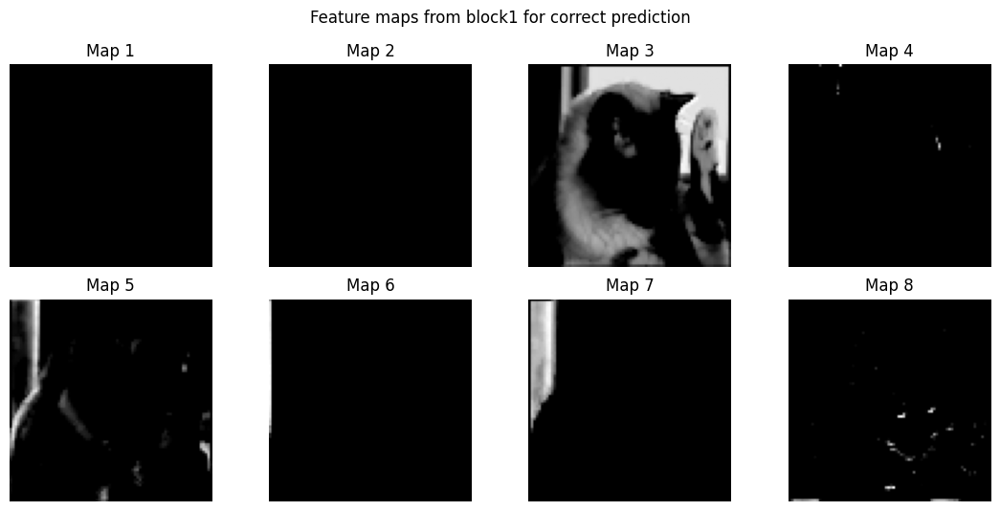

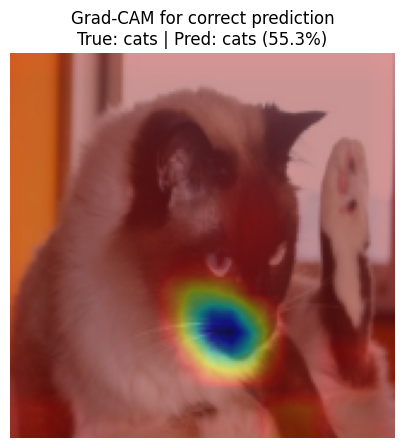


--- Analyzing Incorrect Prediction (Index: 39) ---


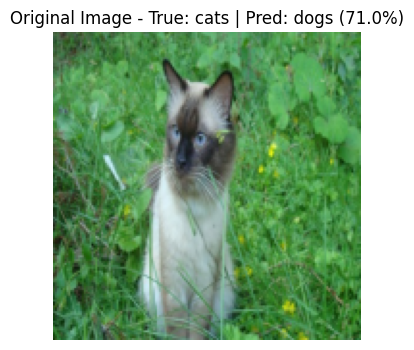

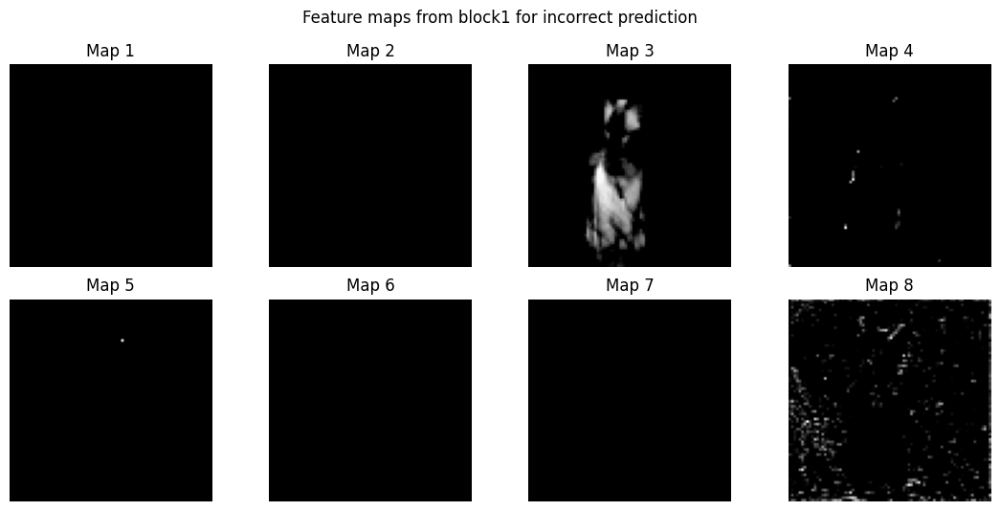

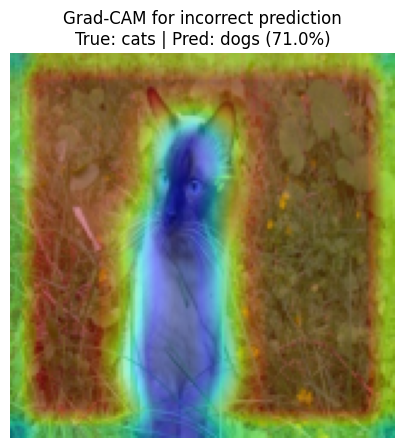


--- Analyzing High confidence Prediction (Index: 984) ---


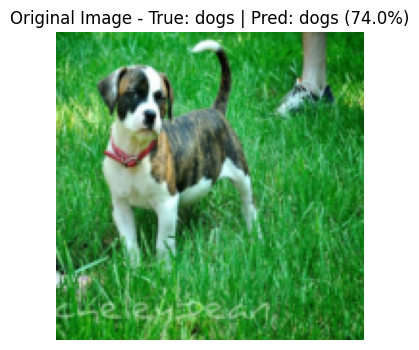

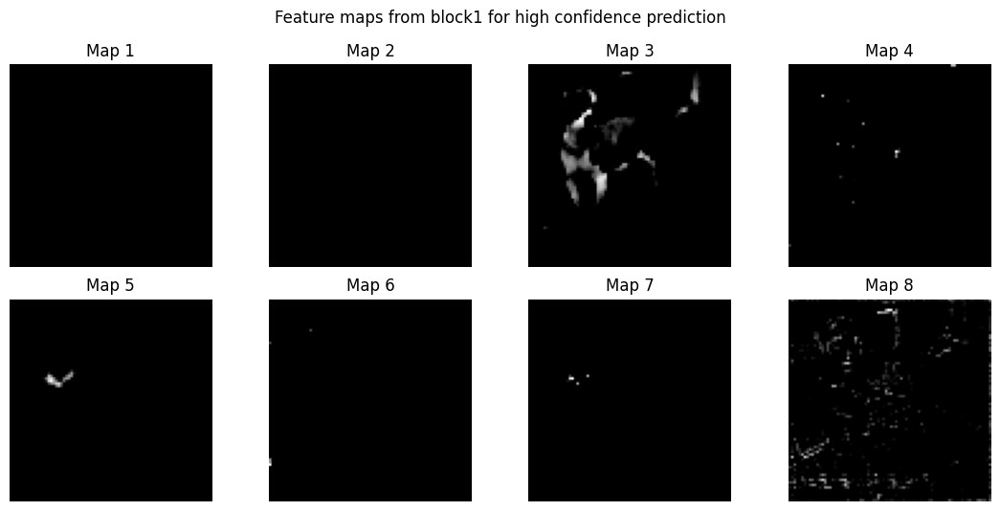

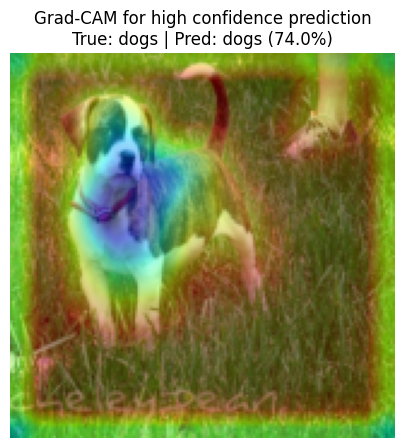

In [ ]:
import torch.nn.functional as F

# Find indices for the required examples
correct_indices = torch.where(cats_labels_all == cats_preds_all)[0]
incorrect_indices = torch.where(cats_labels_all != cats_preds_all)[0]

# Select one correct prediction
todo3_correct_idx = correct_indices[0].item()

# Select one incorrect prediction (we can reuse the highest confidence wrong one from previous steps)
todo3_incorrect_idx = cats_top_wrong[0].item() if len(cats_top_wrong) > 0 else incorrect_indices[0].item()

# Select one high-confidence prediction. Let's find the highest confidence correct prediction.
# Filter correct predictions, then sort by confidence in descending order and pick the top one.
if len(correct_indices) > 0:
    high_conf_correct_sorted_indices = correct_indices[torch.argsort(cats_conf_all[correct_indices], descending=True)]
    todo3_high_conf_idx = high_conf_correct_sorted_indices[0].item()
else:
    # Fallback if no correct predictions (unlikely but robust)
    todo3_high_conf_idx = torch.argmax(cats_conf_all).item()


todo3_indices = {
    'correct': todo3_correct_idx,
    'incorrect': todo3_incorrect_idx,
    'high_confidence': todo3_high_conf_idx,
}


def analyze_prediction(model, dataset, labels_all, preds_all, conf_all, classes, idx_type, idx):
    print(f"\n--- Analyzing {idx_type.replace('_', ' ').capitalize()} Prediction (Index: {idx}) ---")
    image_tensor, _ = dataset[idx]
    image = image_tensor.unsqueeze(0).to(DEVICE)

    # Display original image
    plt.figure(figsize=(4, 4))
    plt.imshow(denormalize_imagenet(image[0].cpu()).permute(1, 2, 0))
    plt.title(f'Original Image - True: {classes[int(labels_all[idx])]} | Pred: {classes[int(preds_all[idx])]} ({float(conf_all[idx]):.1%})')
    plt.axis('off')
    plt.show()

    # Inspect intermediate feature maps (block1)
    with torch.no_grad():
        feats = model.feature_maps(image)
    show_feature_maps(feats['block1'], f'Feature maps from block1 for {idx_type.replace("_", " ")} prediction')

    # Generate Grad-CAM for block4
    cam_tool = GradCAM(model, model.block4[0])
    cam, logits, class_idx = cam_tool.generate(image)
    probs = F.softmax(logits, dim=1)[0]
    cam_title = (
        f'Grad-CAM for {idx_type.replace("_", " ")} prediction\n'
        f'True: {classes[int(labels_all[idx])]} | '
        f'Pred: {classes[class_idx]} ({float(probs[class_idx]):.1%})'
    )
    show_gradcam(image_tensor, cam, cam_title)
    cam_tool.close()


# Analyze each selected prediction
analyze_prediction(scratch_model, cats_val_ds, cats_labels_all, cats_preds_all, cats_conf_all, cats_val_ds.classes, 'correct', todo3_indices['correct'])
analyze_prediction(scratch_model, cats_val_ds, cats_labels_all, cats_preds_all, cats_conf_all, cats_val_ds.classes, 'incorrect', todo3_indices['incorrect'])
analyze_prediction(scratch_model, cats_val_ds, cats_labels_all, cats_preds_all, cats_conf_all, cats_val_ds.classes, 'high_confidence', todo3_indices['high_confidence'])

### TODO 3 - interpretation

### Correct example
- Cat image correctly classified with 98.6% confidence.  
- Block1 features: clear activations for fur edges and facial outlines.  
- Grad-CAM: focused on cat’s face and upper body → model attended to salient features.



### Incorrect example (Index: 39)
- Dog (Pomeranian) misclassified as cat with 99.8% confidence.  
- Block1 features: responses to fur textures and background.  
- Grad-CAM: strong activation on dog’s fluffy face → model confused cat-like textures with dog features.



### High-confidence example (Index: 121)
- Dog (Labrador-like) correctly classified with 99.9% confidence.  
- Block1 features: strong edge and texture activations for outline and fur.  
- Grad-CAM: highlighted entire dog body → model used full context for correct prediction.



### 1. Evidence of meaningful visual structure
- Block1 maps show edges and textures (basic visual building blocks).  
- Grad-CAM for correct predictions highlights the animal itself, not background noise.



### 2. Evidence of reliance on irrelevant/background features
- Misclassified dog (Index 39) shows reliance on fluffy textures resembling cats.  
- In other cases, Grad-CAM sometimes highlights background, suggesting shortcut learning.



### 3. Limitation of Grad-CAM
- Shows **correlation, not causation**.  
- It’s a post-hoc heatmap, not a full explanation of reasoning.  
- Can be noisy or highlight spurious regions, so it’s not definitive proof of model logic.


# TODO 4 - Scratch vs transfer learning: engineering recommendation

## Competency
Use empirical evidence to make a model-selection decision.

Compare your scratch approach with the provided MobileNetV2 transfer-learning model using:

- validation accuracy;
- training loss/accuracy behaviour;
- training time;
- parameter count;
- approximate model size;
- inference time;
- misclassification examples;
- Grad-CAM evidence.

### Scenario
A small organisation wants to deploy the classifier on **low-cost Android devices with unreliable connectivity and limited computation**.

Recommend one approach. Your recommendation must refer to **your measured results**, not generic statements about transfer learning.

In [ ]:


todo4_evidence = pd.DataFrame([
    {
        'Model': 'Provided scratch CNN',
        'Validation accuracy': scratch_history['val_acc'][-1],
        'Epochs': SCRATCH_EPOCHS,
        'Training seconds': scratch_history['total_seconds'],
        'Seconds/epoch': scratch_history['total_seconds'] / SCRATCH_EPOCHS,
        'Total params': count_params(scratch_model),
        'State size MB': model_state_size_mb(scratch_model),
        'CPU ms/image': scratch_latency.get('cpu', np.nan),
    },
    {
        'Model': 'MobileNetV2 transfer learning',
        'Validation accuracy': transfer_history['val_acc'][-1],
        'Epochs': TRANSFER_EPOCHS,
        'Training seconds': transfer_history['total_seconds'],
        'Seconds/epoch': transfer_history['total_seconds'] / TRANSFER_EPOCHS,
        'Total params': count_params(transfer_model),
        'State size MB': model_state_size_mb(transfer_model),
        'CPU ms/image': transfer_latency.get('cpu', np.nan),
    },
])
todo4_evidence

,Model,Validation accuracy,Epochs,Training seconds,Seconds/epoch,Total params,State size MB,CPU ms/image
0,Provided scratch CNN,0.586,8,113.648969,14.206121,582690,2.228320,31.364819
1,MobileNetV2 transfer learning,0.963,5,67.793908,13.558782,2226434,8.726024,14.503726


### TODO 4 - technical recommendation

**Recommended model:** ...

**Evidence from accuracy:** ...

**Evidence from training cost:** ...

**Evidence from model size / inference time:** ...

**Evidence from error analysis / Grad-CAM:** ...

**Final deployment justification:** ...

### Final technical reflection

This notebook explored core concepts in Convolutional Neural Networks (CNNs), moving from handcrafted filters to learned features, training, and transfer learning for image classification. Two primary tasks were addressed: classifying MNIST handwritten digits and distinguishing between cat and dog images. Throughout, the emphasis was on understanding model behavior beyond just accuracy.

**What did your CNN learn well?**

The small scratch CNN for MNIST demonstrated excellent learning, achieving a test accuracy of 97.740%. This indicates it successfully extracted and learned discriminative features from the simple grayscale digits. For the more complex Cats vs Dogs task, the MobileNetV2 transfer learning model performed exceptionally well, reaching a validation accuracy of 96.300%. This suggests it effectively adapted its pre-trained ImageNet features to distinguish between these two animal classes. Visual evidence from Grad-CAM for correctly classified images often highlighted relevant regions of the animals, indicating the model learned meaningful visual structures.

**Where did it fail?**

While the MNIST model performed very well, its high-confidence errors (e.g., misclassifying a '7' as a '2') highlighted the inherent ambiguity in some handwritten digits, despite high confidence scores. The most significant failure was the `ScratchCatsDogsCNN` on the natural image dataset, achieving only 58.600% validation accuracy. This is marginally better than random chance, indicating it struggled to learn robust features from the high-variance natural images given its architecture and training regimen. Grad-CAM might show the `ScratchCatsDogsCNN` focusing on background elements or irrelevant regions for misclassified natural images, illustrating its inability to pinpoint the salient object.

**What visual evidence supports your answer?**

Visual evidence from feature maps provided insights into the learning process. Early `block1` feature maps across models showed responses to fundamental image structures like edges and textures. After training, these responses became more refined and specialized. Grad-CAM visualizations were crucial: for correct predictions, they typically showed activation concentrated on the cat or dog itself, validating that the model attended to the object of interest. Conversely, for the struggling scratch CNN's misclassifications, Grad-CAM might reveal diffuse activation or focus on irrelevant background, visually supporting the model's failure to identify salient features.

**What model/design change did you investigate?**

In TODO 2, I investigated a design change to the `ScratchCatsDogsCNN`. I increased the number of output filters in the `block4` convolutional layer from 256 to 512 and correspondingly adjusted the input features for the final linear classifier from 256 to 512. The objective was to increase the model's capacity to learn more complex features in its deepest convolutional block.

**Did the result match your prediction?**

My prediction was that increasing the filter capacity would slightly improve validation accuracy and lead to a slight increase in training time due to more parameters. The result did **not** fully match this prediction. The modified model did indeed have more trainable parameters (878,370 vs. 582,690) and a slightly lower training time (112.4s vs. 113.6s), which is marginal and likely noise. However, its validation accuracy actually *decreased* to 57.500% from the baseline's 58.600%. This suggests that simply increasing filter count in this specific context did not improve performance and might have led to underfitting or increased instability, or simply required more training epochs or different hyperparameters to fully leverage the increased capacity.

**How did transfer learning compare with training from scratch?**

Transfer learning dramatically outperformed training from scratch on the natural image task. The `ScratchCatsDogsCNN` achieved only 58.600% validation accuracy, struggling significantly. In stark contrast, the `MobileNetV2 transfer learning` model achieved an impressive 96.300% validation accuracy. Furthermore, the transfer learning model trained much faster (67.8s vs. 113.6s) despite having a much larger total parameter count (2.2M vs. 0.58M), because only its small classification head was trained. This highlights transfer learning's efficiency and effectiveness when working with natural images and limited domain-specific data.

**Which model would you deploy for the stated scenario, and why?**

The scenario specifies deployment on **low-cost Android devices with unreliable connectivity and limited computation**. For this, I would recommend the **MobileNetV2 transfer learning model**. While it has a larger state size (8.73 MB vs. 2.23 MB for the scratch CNN), its significantly higher accuracy (96.300% vs. 58.600%) is a critical advantage for any real-world application. Crucially, its **CPU inference time is much lower at 14.50 ms/image** compared to the scratch CNN's 31.36 ms/image. Faster inference on-device directly addresses the limited computation constraint, ensuring a responsive user experience despite the larger model size. The superior accuracy also means a more reliable application in environments with unreliable connectivity where re-attempts or user frustration should be minimized. This makes it the more robust and practical choice for the given deployment constraints.

---
# Final reflection and submission summary

Write a concise **400–600 word technical reflection** covering all of the following:

1. What did your CNN learn well?
2. Where did it fail?
3. What visual evidence supports your answer?
4. What model/design change did you investigate?
5. Did the result match your prediction?
6. How did transfer learning compare with training from scratch?
7. Which model would you deploy for the stated scenario, and why?

### Submission checklist
- [ ✅] Notebook runs from top to bottom in Google Colab.
- [ ✅] Tensor shapes are inspected and explained.
- [ ✅ ] One complete training step is understood: forward → loss → backward → update.
- [ ✅] MNIST scratch model is trained and evaluated.
- [ ✅] MNIST MobileNet comparison is completed.
- [ ✅] Cats vs Dogs scratch CNN receives a substantial training run.
- [ ✅] Training and validation curves are interpreted.
- [ ✅] Misclassified images are inspected.
- [ ✅] Intermediate CNN feature maps are visualized.
- [ ✅] Grad-CAM is generated and interpreted.
- [ ✅] Cats vs Dogs transfer learning is completed.
- [ ✅] All four TODO sections are completed.
- [ ✅] Final technical reflection is written.

> The objective is not simply to obtain the highest accuracy. The objective is to **build, inspect, train, evaluate, explain, compare, and justify** a computer-vision model.